# **DSA8003 COURSEWORK**

---

**Overview**

- Clustering Task [30% mark]:

    - Data: id_clustering.csv

    - Apply hierarchical clustering and k-means to cluster the provided data.

    - Use appropriate methods to determine the number of clusters.
- Classification Task [70% mark]:
    - Data: id_classification.csv
    - For the assigned dataset, complete the following tasks:
        1. Check if it has missing values and apply an appropriate data imputation
        method [15% mark]
        2. Create a training set/validation set/test set with an appropriate stratified
        split [5% mark]
        Save them in training.csv, validation.csv and test.csv files
        3. Use the training.csv to train Classifiers for your data [50% mark]:
            - Build a classification tree using the training set
            - Build a Naïve Bayes classifier
            - Build a logistic regression classifier
            - Design your own classifier using k-means clustering
                - Apply k-means clustering algorithms to training.csv
                - Find the centers of each cluster and their corresponding classes
                - Classify the data in test.csv by the shortest distance to the center
                of each class using the Manhattan distance $\newline$
                https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
           - Consider processing data with and without PCA for the above classifiers.
    - Use the test.csv to report their performances. Make a recommendation as to which
    classifier performs the best for your dataset and what this decision is based on [1].
    
---

**Datasets Overview**

The MNIST (Modified National Institute of Standards and Technology) dataset is a large collection of handwritten digit images ranging from $0$ to $9$. The MNIST dataset is commonly used for training various image processing systems and also widely used in the field of machine learning. It consists of greyscale images of handwritten digits.

Key characteristics of the MNIST dataset:
- Each image represents a single handwritten digit $(0-9)$,
- Each image is $28 \times 28$ pixels in size,
- Each image can be represented as a $784$-dimensional vector by flattening the pixel grid,
- Pixel values represent greyscale intensity and range from $0$ to $255$,
- Each image in the original dataset has a corresponding digit label [2].

**Formation of the Coursework Datasets**

Two datasets were provided for this coursework:
- `40360767_clustering.csv`
- `40360767_classification.csv`

Both datasets are random samples drawn from the original MNIST dataset, where each row represents a single handwritten digit image [1].

---

**Importing Packagaes**

In [1]:
# Core Python libraries
import numpy as np
import pandas as pd

# Show full content of each cell in dataframes without truncation
pd.set_option("display.max_colwidth", None)

# Statistics
from scipy import stats
from scipy.stats import norm, mode

# Plotting and Visualisation
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
colours = plt.cm.tab10.colors

# Data preprocessing / Scaling / Imputation
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Clustering
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
# Dimensionality reduction
from sklearn.decomposition import PCA

# Model evaluation metrics
from sklearn.metrics import (silhouette_score, calinski_harabasz_score as ch_score, davies_bouldin_score as db_score, accuracy_score, f1_score, pairwise_distances)

# Classification
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

# Classifiers
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

# R integration in Python
import rpy2.robjects as robjects
from rpy2.robjects.packages import importr
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects import globalenv

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.


**Setting Seed for Reproducibility**

In [2]:
# Reproducibility
seed = 123
rng = np.random.default_rng(seed)
np.random.seed(seed)

---

## **Clustering**

Cluster analysis is an unsupervised data reduction technique used to identitfy subgroups of observations within a dataset. When performing cluster analysis the class label of each observation is not known in advance and clusters are formed based solely on similarities between observations [3].

- The clustering dataset is formed from a random sample of handwritten digit images taken from the MNIST dataset,
- Each row represents a single image and each column corresponds to a pixel intensity value,
- No class labels are provided in this dataset making it suitable for unsupervised machine learning,
- This means internal validation metrics are required to evaluate clustering compactness and separation,
- Since the original MNIST dataset contains digits ranging from $0$ to $9$ the clustering dataset may contain up to $10$ distinct clusters,
- However, as the dataset is a random sample not all digit classes are guaranteed to be present in the dataset.

---

**Loading Clustering Dataset**

In [3]:
# Load clustering CSV file corresponding to student ID
df_clustering = pd.read_csv("40360767_clustering.csv")

print("Clustering dataset successfully loaded")

Clustering dataset successfully loaded


**Initial Inspection of Dataset**

In [4]:
# Get basic information about the dataset
# Number of features
num_columns = df_clustering.shape[1]

# Number of images
num_rows = df_clustering.shape[0]

# Investigating clustering dataset
print("Shape of clustering dataset: ", df_clustering.shape)
print("Columns in clustering dataset: ", df_clustering.columns.tolist())
print("Number of columns in clustering dataset: ", num_columns)
print("Number of rows in clustering dataset: ", num_rows)

# Display first 5 rows in clustering dataset
display(df_clustering.head())

# Display summary statistics of unscaled clustering dataset
print("Summary statistics of unscaled clustering dataset:")
display(df_clustering.describe())

# Checks for missing values in the clustering dataset and prints the total number of missing values
print("Number of missing values in clustering dataset: ", df_clustering.isnull().sum().sum())

Shape of clustering dataset:  (7569, 7)
Columns in clustering dataset:  ['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6']
Number of columns in clustering dataset:  7
Number of rows in clustering dataset:  7569


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6
0,0.99831,-0.80325,-0.07966,1.33853,-0.96543,1.30062,0.72089
1,1.33426,-1.57393,1.64217,-2.77559,-2.22682,1.93562,3.20747
2,2.85749,-0.32264,-1.72321,-1.49470,-0.54065,0.60164,0.56509
3,-0.31189,1.85892,-1.21140,-0.90995,-0.29595,0.63972,-0.06184
4,-2.01225,-2.55170,-1.10264,0.63622,4.74005,2.96288,-2.33810


Summary statistics of unscaled clustering dataset:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6
count,7569.000000,7569.000000,7569.000000,7569.000000,7569.000000,7569.000000,7569.000000
mean,-0.003393,-0.110268,-0.081960,0.165022,0.067439,0.266111,-0.022839
std,1.523528,1.657506,2.359984,1.604728,1.624543,1.565451,1.621032
min,-5.294520,-5.953340,-11.561320,-5.443620,-7.548150,-5.773300,-6.089600
25%,-1.090030,-1.282900,-1.587510,-0.953540,-1.062360,-0.833970,-1.151320
50%,0.046510,-0.163100,-0.023360,0.163550,0.061890,0.337500,-0.039950
75%,1.109840,1.024550,1.435260,1.288690,1.225160,1.367500,1.064350
max,6.472660,6.347230,11.063590,6.576640,6.823410,6.051810,7.627460


Number of missing values in clustering dataset:  0


**Data Scaling**

In [5]:
# Converts the clustering dataframe to a numpy array for scaling
X = df_clustering[df_clustering.columns].to_numpy()

# Initialises StandardScaler to standardise features (mean=0, std=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Converts scaled data to a dataframe using original column names
df_clustering_scaled = pd.DataFrame(X_scaled, columns=df_clustering.columns)

# Display first 5 rows in scaled clustering dataset
display(df_clustering_scaled.head())

# Display summary statistics of scaled clustering dataset
print("Summary statistics of scaled clustering dataset:")
display(df_clustering_scaled.describe())

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6
0,0.657533,-0.418115,0.000975,0.731330,-0.635833,0.660881,0.458830
1,0.878055,-0.883109,0.730617,-1.832588,-1.412343,1.066542,1.992880
2,1.877926,-0.128136,-0.695496,-1.034338,-0.374339,0.214348,0.362712
3,-0.202502,1.188122,-0.478611,-0.669922,-0.223702,0.238675,-0.024061
4,-1.318643,-1.473052,-0.432523,0.293651,2.876453,1.722792,-1.428358


Summary statistics of scaled clustering dataset:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6
count,7.569000e+03,7.569000e+03,7.569000e+03,7.569000e+03,7.569000e+03,7.569000e+03,7.569000e+03
mean,6.571276e-18,2.065258e-17,-3.755015e-18,1.783632e-17,9.387538e-19,3.755015e-18,2.816261e-18
std,1.000066e+00,1.000066e+00,1.000066e+00,1.000066e+00,1.000066e+00,1.000066e+00,1.000066e+00
min,-3.473174e+00,-3.525452e+00,-4.864491e+00,-3.495304e+00,-4.688146e+00,-3.858191e+00,-3.742778e+00
25%,-7.132845e-01,-7.075144e-01,-6.379914e-01,-6.970873e-01,-6.955026e-01,-7.027710e-01,-6.961960e-01
50%,3.275723e-02,-3.187630e-02,2.483239e-02,-9.171706e-04,-3.415928e-03,4.560584e-02,-1.055653e-02
75%,7.307428e-01,6.846995e-01,6.429368e-01,7.002697e-01,7.126914e-01,7.036066e-01,6.707212e-01
max,4.250977e+00,3.896170e+00,4.723035e+00,3.995718e+00,4.158966e+00,3.696111e+00,4.719712e+00


**Dimensionality Reduction for Visualisation Using PCA**

Principal components analysis (PCA) is a data-reduction technique that transforms a large set of correlated variables into a smaller set of uncorrelated variables called principal components [4].

In [6]:
# Applys Principal Component Analysis (PCA) to reduce dimensions to 2 for visualisation
pca = PCA(n_components=2, random_state=seed)
X_clustering_pca = pca.fit_transform(X_scaled)

# Calculates total variance explained by the first 2 components
explained_var = pca.explained_variance_ratio_.sum()

print(f"Variance explained by 2 components: {explained_var * 100:.2f}%")

Variance explained by 2 components: 58.84%


### **K-means Clustering**

K-means clustering is a partition-based clustering algorithm in which each cluster is represented by the mean (centroid) of the obervations assigned to it. The algorithm requires the number of clusters $k$ to be specified in advance and partitions the data into $k$ distinct groups by minimising the within-cluster sum of squared distances [5]. 


In [7]:
# Delcaring variables
k_values = range(2, 11)
kmeans_scores = []

# Loops through different values of k to compute clustering metrics
for k in k_values:
    
    # Initialise k-means
    kmeans = KMeans(n_clusters=k, n_init=50, random_state=seed)

    # Fit model and predict clusters
    labels = kmeans.fit_predict(X_scaled)

    # Compute clustering evaluation metrics
    # Sum of squared distances within clusters
    inertia = kmeans.inertia_

    # Silhouette score
    sil = silhouette_score(X_scaled, labels)

    # Calinski-Harabasz
    ch = ch_score(X_scaled, labels)
    
    # Davies-Bouldin
    db = db_score(X_scaled, labels)

    # Store results
    kmeans_scores.append({'k': k, "inertia": inertia, "sil": sil, "ch": ch, "db": db})

# Convert results to a dataframe for easy viewing
kmeans_scores_df = pd.DataFrame(kmeans_scores)

# Rounds all values to 3 decimal places
kmeans_scores_df = kmeans_scores_df.round(3)

display(kmeans_scores_df)

,k,inertia,sil,ch,db
0,2,39463.813,0.220,2592.242,1.615
1,3,34993.273,0.167,1944.813,1.831
2,4,31955.607,0.159,1659.307,1.774
3,5,29362.353,0.160,1521.234,1.644
4,6,27098.357,0.166,1444.855,1.541
5,7,25478.678,0.167,1360.535,1.498
6,8,24092.136,0.166,1295.291,1.456
7,9,22958.741,0.168,1235.825,1.435
8,10,21992.584,0.163,1183.514,1.452


**Selecting Optimal $k$ for k-means**

In [8]:
# Declaring variables
winners_kmeans = []

# Silhouette Score (max)
winners_kmeans.append(("Silhouette", *kmeans_scores_df.loc[kmeans_scores_df["sil"].idxmax(), ['k', "sil"]]))

# Calinski-Harabasz Score (max)
winners_kmeans.append(("Calinski-Harabasz", *kmeans_scores_df.loc[kmeans_scores_df["ch"].idxmax(), ['k', "ch"]]))

# Davies-Bouldin Score (min)
winners_kmeans.append(("Davies-Bouldin", *kmeans_scores_df.loc[kmeans_scores_df["db"].idxmin(), ['k', "db"]]))

# Create a dataframe showing optimal k by each metric
vote_kmeans_df = pd.DataFrame(winners_kmeans, columns=["Method", "Optimal k", "Score"]).round(3)

display(vote_kmeans_df)

,Method,Optimal k,Score
0,Silhouette,2.0,0.220
1,Calinski-Harabasz,2.0,2592.242
2,Davies-Bouldin,9.0,1.435


**Plot Evaluation Metrics**

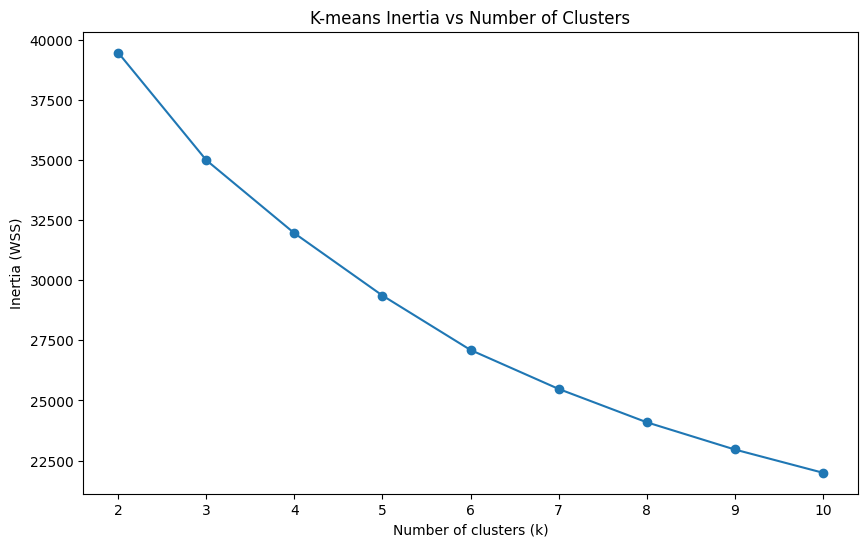

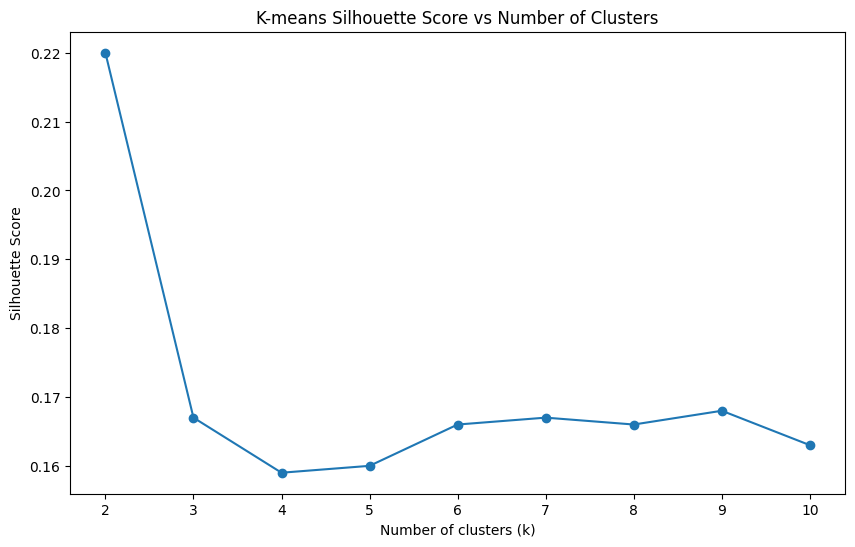

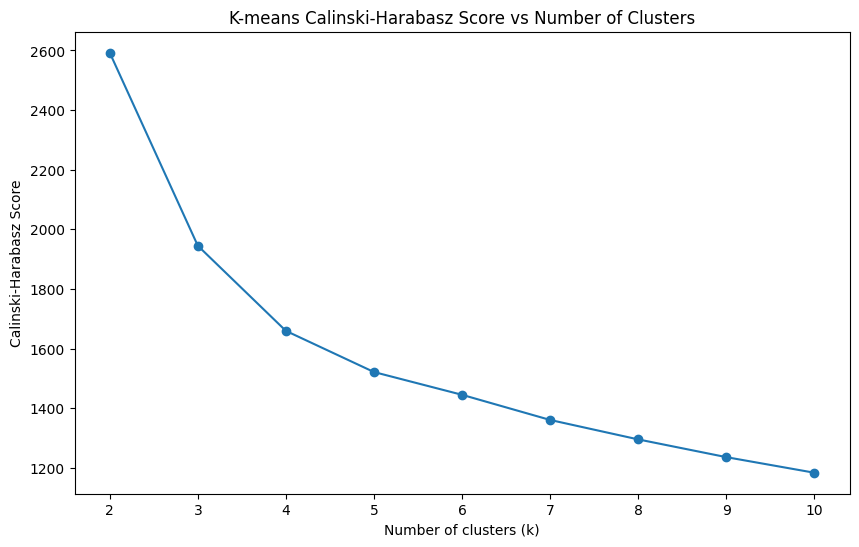

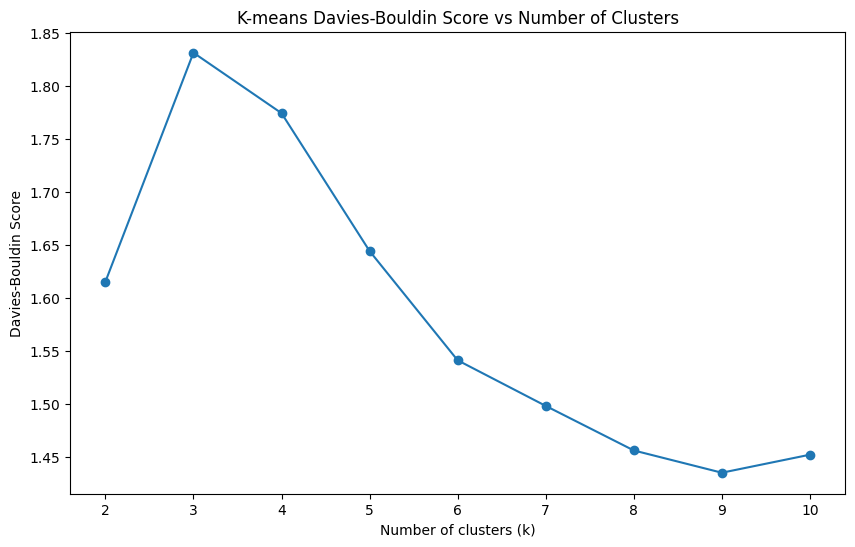

In [9]:
# Plot evaluation metrics vs k
# Inertia Plot
plt.figure(figsize=(10, 6))
plt.plot(kmeans_scores_df['k'], kmeans_scores_df["inertia"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (WSS)")
plt.title("K-means Inertia vs Number of Clusters")
plt.show()

# Silhouette score plot
plt.figure(figsize=(10, 6))
plt.plot(kmeans_scores_df['k'], kmeans_scores_df["sil"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-means Silhouette Score vs Number of Clusters")
plt.show()

# Calinski-Harabasz score plot
plt.figure(figsize=(10, 6))
plt.plot(kmeans_scores_df['k'], kmeans_scores_df["ch"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("K-means Calinski-Harabasz Score vs Number of Clusters")
plt.show()

# Davies-Bouldin score plot
plt.figure(figsize=(10, 6))
plt.plot(kmeans_scores_df['k'], kmeans_scores_df["db"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Davies-Bouldin Score")
plt.title("K-means Davies-Bouldin Score vs Number of Clusters")
plt.show()

### **Selection of the Optimal Number of Clusters for k-means clustering**

To determine the optimal number of clusters for k-means clustering, several evaluation metrics were considered:
- **Inertia**, which represents the within-cluster sum of squared distances.
- **Silhouette Score**, which measures how well each observation fits within its assigned cluster compared to other clusters (higher values indicate better-defined clusters).
- **Calinski–Harabasz Index**, which evaluates the ratio of between-cluster dispersion to within-cluster dispersion(higher values indicate better clusters).
- **Davies–Bouldin Index**, which measures the average similaritybetween clusters where lower values indicate better separation between clusters [6].  

##### **Inertia**

The inertia plot was examined to identify a potential elbow point that would indicate diminishing returns from increasing the number of clusters. While a slight change in slope is observable around $k = 6$ the elbow is not clearly defined. This suggests that inertia alone is insufficient for selecting an optimal number of clusters in this high-dimensional dataset.

##### **Silhouette Score and Calinski–Harabasz Index**

Both the Silhouette Score and Calinski–Harabasz Index suggest an optimal value of $k = 2$, which indicates a strong separation between the two separate groups. This result is consistent with the tendency of these metrics to favour compact and well-separated clusters.

However, such a low value of $k$ may lead to overly rough clustering and may not capture finer distinctions between observations. In the context of the handwritten digit data this level of aggregation is unlikely to reflect the more detailed structure present in the dataset.

##### **Davies–Bouldin Index**

The Davies–Bouldin Index reaches its minimum at $k = 9$, which indicates improved cluster separation and reduced similarity between clusters at this value. Unlike the Silhouette score and Calinski–Harabasz index the Davies–Bouldin Index is more sensitive to intra-cluster compactness and inter-cluster similarity, which makes it well-suited for evaluating more detailed cluster structures [7].

A value of $k$ close to $10$ is also plausible given that the dataset is a random sample drawn from the MNIST dataset, which contains handwritten digits from $0$ to $9$. While the sample may not include all digit classes selecting $k = 9$ supports a more detailed and interpretable partition of the data without assuming the presence of all ten digits.

##### **Conclusion**

Based on the combined evidence from the evaluation metrics and the domain knowledge of the MNIST dataset we select $k = 9$ as the optimal number of clusters for k-means clustering. This choice balances the limitations of inertia based selection with metric based evidence supporting improved separation and compactness at higher values of $k$.

---

**Final k-means Clustering** 

In [10]:
optimal_k_kmeans = 9

In [11]:
# Initialise k-means
kmeans_final = KMeans(n_clusters=optimal_k_kmeans, n_init=50, random_state=seed)

# Fit model and predict clusters
kmeans_labels = kmeans_final.fit_predict(X_scaled)

# Add cluster labels to the original dataframe
df_clustering["kmeans_cluster"] = kmeans_labels

In [12]:
# Creates a summary table showing cluster counts and percentages
counts_kmeans = df_clustering["kmeans_cluster"].value_counts().sort_index()
summary = pd.DataFrame({"Cluster": counts_kmeans.index, "Count": counts_kmeans.values, "Percentage (%)": (counts_kmeans.values / counts_kmeans.values.sum() * 100).round(2)})

# Add a total row
summary.loc["Total"] = ['', summary["Count"].sum(), '']

display(summary)

,Cluster,Count,Percentage (%)
0,0,962,12.71
1,1,878,11.6
2,2,1125,14.86
3,3,1057,13.96
4,4,829,10.95
5,5,818,10.81
6,6,695,9.18
7,7,571,7.54
8,8,634,8.38
Total,,7569,


In [13]:
# Evaluate final k-means clustering
inertia = round(kmeans_final.inertia_, 3)
sil_kmeans = round(silhouette_score(X_scaled, kmeans_labels), 3)
ch_kmeans = round(ch_score(X_scaled, kmeans_labels), 3)
db_kmeans = round(db_score(X_scaled, kmeans_labels), 3)

# Print final k-means scores
print("K-means Clustering Final Evaluation Metrics:")
print("Inertia: ", inertia)
print("Silhouette Score: ", sil_kmeans)
print("Calinski-Harabasz Score: ", ch_kmeans)
print("Davies-Bouldin Score: ", db_kmeans)

K-means Clustering Final Evaluation Metrics:
Inertia:  22958.741
Silhouette Score:  0.168
Calinski-Harabasz Score:  1235.825
Davies-Bouldin Score:  1.435


**Plots to Look at Distribution of Clusters in k-means Clustering**

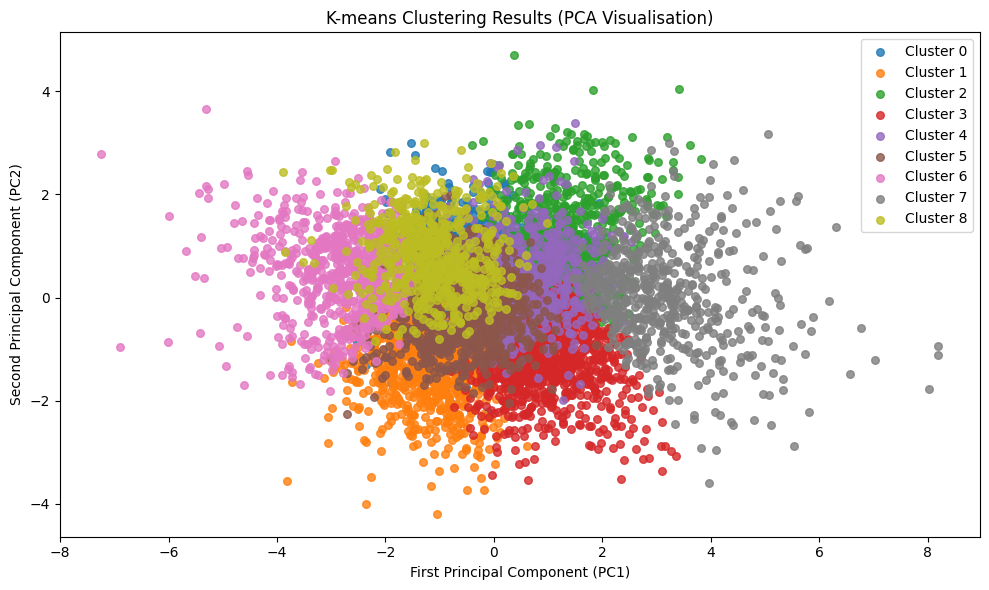

In [14]:
# Visualise k-means clusters using PCA
plt.figure(figsize=(10,6))

# Loop through each unique cluster label
for i, cluster in enumerate(np.unique(kmeans_labels)):

    # Select points belonging to the current cluster
    cluster_points = X_clustering_pca[kmeans_labels == cluster]

    # Scatter plot of the points within the current cluster
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], color=colours[i % 10], label=f"Cluster {cluster}", s=30, alpha=0.8)

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("K-means Clustering Results (PCA Visualisation)")

plt.legend()
plt.tight_layout()
plt.show()

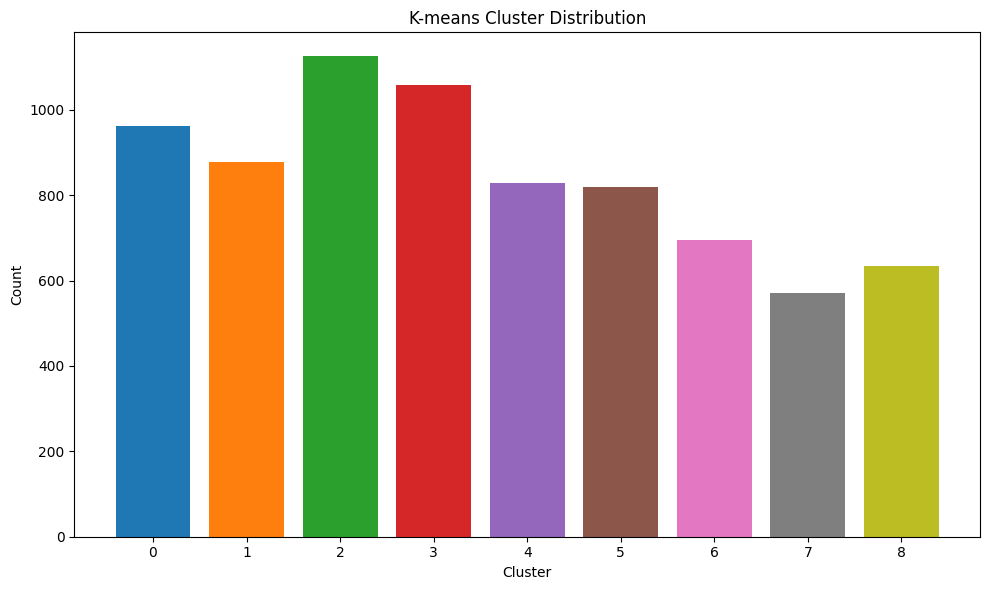

In [15]:
# Visualise k-means cluster distribution
plt.figure(figsize=(10,6))

# Bar chart showing number of points in each k-means cluster
plt.bar(counts_kmeans.index, counts_kmeans.values, color=colours[:len(counts_kmeans)])
plt.xticks(counts_kmeans.index)
plt.xlabel("Cluster")
plt.ylabel("Count")
plt.title("K-means Cluster Distribution")
plt.tight_layout()
plt.show()

### **Hierarchical Clustering**

Hierarchical clustering is a clustering method that produces a series of nested partitions, each representing a different level of grouping among observations based on the available data. These partitions reflect how clusters are formed or divided as the level of similarity between observations changes.

Hierarchical clustering methods can be classified as agglomerative or divisive depending on how the hierarchical structure is constructed. In agglomerative clustering, which is the approach used in this assignment, each observation initially forms its own cluster. Clusters are then merged step by step according to a specified criterion until a desired number of clusters is reached.

The number of clusters can be controlled by specifying a termination condition, which allows the user to select an appropriate level of clustering from the hierarchy [8].

In [16]:
# Compute pairwise Euclidean distances
D_euc = pdist(X_scaled, metric="euclidean")

# Compute hierarchical clustering linkage matrix using Ward's method
Z_ward = linkage(D_euc, method="ward")

**Plot Full Dendrogram**

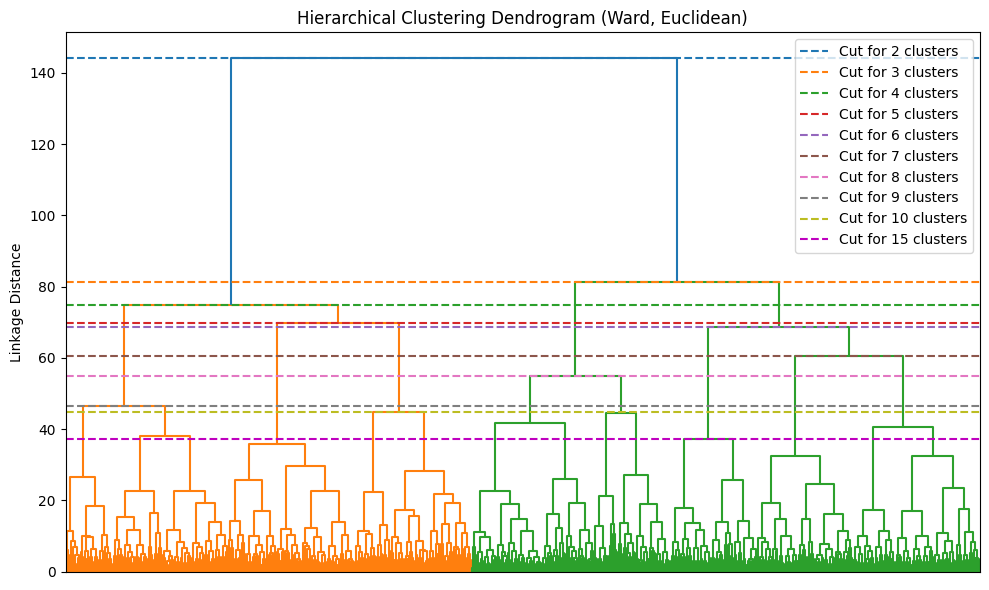

In [17]:
# Dendrogram for visualising cluster structure
plt.figure(figsize=(10, 6))

# Create dendrogram from the linkage matrix
dendrogram(Z_ward, no_labels=True, color_threshold=None)

# Add horizontal lines showing potential cluster cuts for k = 2 to k = 10
for i in range(2, 11):
    plt.axhline(y=Z_ward[-i + 1, 2], color=colours[i-2], linestyle="--", label=f"Cut for {i} clusters")

# Additional cut for k = 15
plt.axhline(y=Z_ward[-15 + 1, 2], color='m', linestyle="--", label=f"Cut for 15 clusters")

plt.ylabel("Linkage Distance")
plt.title("Hierarchical Clustering Dendrogram (Ward, Euclidean)")
plt.tight_layout()
plt.legend(loc="upper right")
plt.show()

**Plot Truncated Dendrogram for Easier Visualisation**

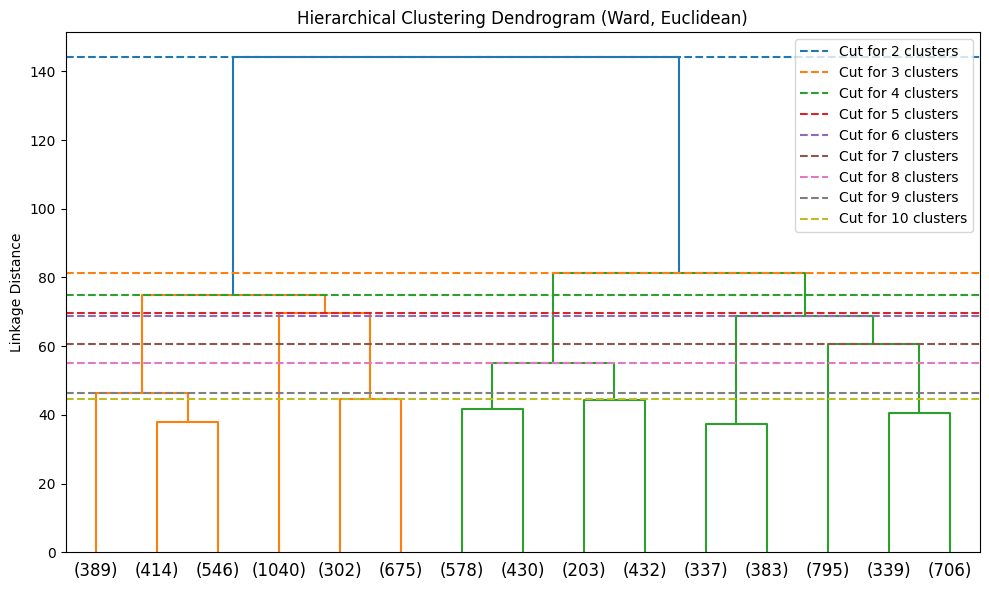

In [18]:
# Truncate dendrogram to show last 15 merges
plt.figure(figsize=(10, 6))

# Truncate dendrogram to show only last 15 merges
dendrogram(Z_ward, truncate_mode="lastp", p=15)

# Add horizontal lines showing potential cluster cuts for k = 2 to k = 10
for i in range(2, 11):
    plt.axhline(y=Z_ward[-i + 1, 2], color=colours[i-2], linestyle="--", label=f"Cut for {i} clusters")

plt.ylabel("Linkage Distance")
plt.title("Hierarchical Clustering Dendrogram (Ward, Euclidean)")
plt.tight_layout()
plt.legend(loc="upper right")
plt.show()

In [19]:
# Delcaring variables
k_values = range(2, 11)
hierarchical_scores = []

# Loops through different values of k to compute clustering metrics
for k in k_values:
    
    # Get cluster labels for k clusters
    labels = fcluster(Z_ward, t=k, criterion="maxclust") - 1

    # Compute clustering evaluation metrics
    # Silhouette score
    sil = silhouette_score(X_scaled, labels)

    # Calinski-Harabasz
    ch = ch_score(X_scaled, labels)
    
    # Davies-Bouldin
    db = db_score(X_scaled, labels)

    # Store results
    hierarchical_scores.append({'k': k, "sil": sil, "ch": ch, "db": db})

# Convert results to a dataframe for easy viewing
kmeans_scores_df = pd.DataFrame(kmeans_scores)

# Rounds all values to 3 decimal places
hierarchical_scores_df = pd.DataFrame(hierarchical_scores).round(3)

display(hierarchical_scores_df)

,k,sil,ch,db
0,2,0.170,1845.646,1.898
1,3,0.096,1318.418,2.288
2,4,0.086,1139.318,2.231
3,5,0.086,1050.189,2.042
4,6,0.094,1015.361,1.904
5,7,0.093,975.670,1.770
6,8,0.097,938.242,1.757
7,9,0.099,890.362,1.738
8,10,0.099,853.175,1.696


**Selecting Optimal $k$ for Hierarchical**

In [20]:
# Declaring variables
winners_hierarchical = []

# Silhouette Score (max)
winners_hierarchical.append(("Silhouette", *hierarchical_scores_df.loc[hierarchical_scores_df["sil"].idxmax(), ['k', "sil"]]))

# Calinski-Harabasz Score (max)
winners_hierarchical.append(("Calinski-Harabasz", *hierarchical_scores_df.loc[hierarchical_scores_df["ch"].idxmax(), ['k', "ch"]]))

# Davies-Bouldin Score (min)
winners_hierarchical.append(("Davies-Bouldin", *hierarchical_scores_df.loc[hierarchical_scores_df["db"].idxmin(), ['k', "db"]]))

# Create a dataframe showing optimal k by each metric
vote_kmeans_df = pd.DataFrame(winners_hierarchical, columns=["Method", "Optimal k", "Score"]).round(3)

display(vote_kmeans_df)

,Method,Optimal k,Score
0,Silhouette,2.0,0.170
1,Calinski-Harabasz,2.0,1845.646
2,Davies-Bouldin,10.0,1.696


**Plot Evaluation Metrics**

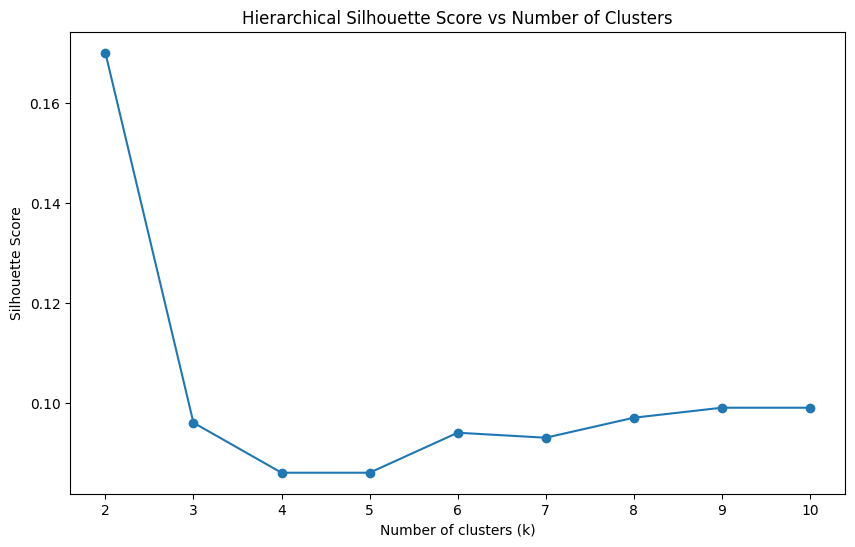

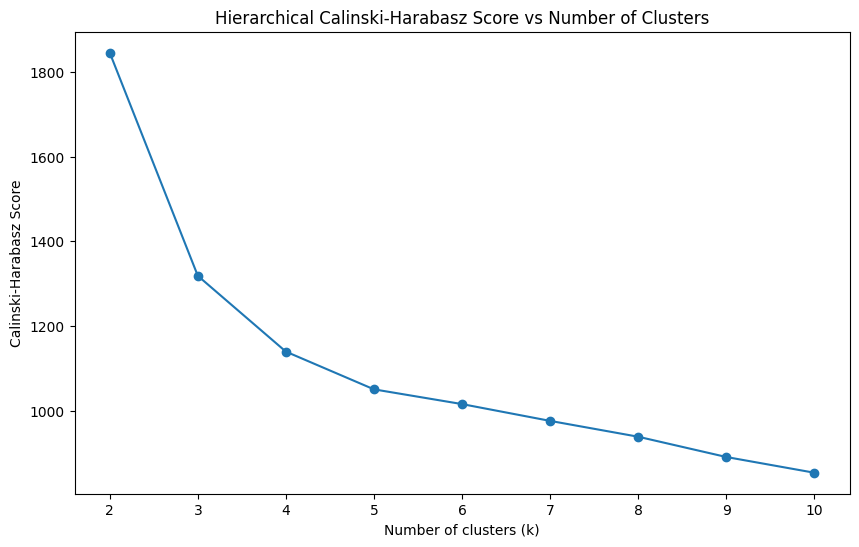

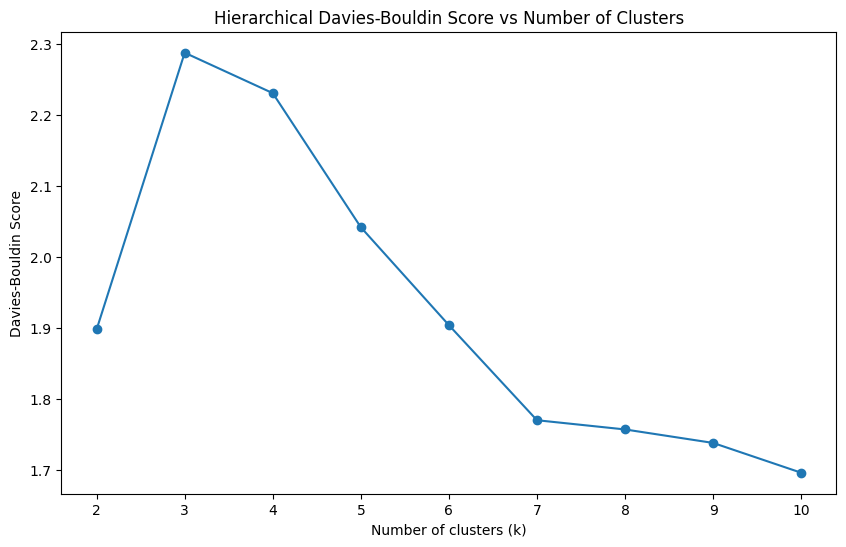

In [21]:
# Plot evaluation metrics vs k
# Silhouette score plot
plt.figure(figsize=(10, 6))
plt.plot(hierarchical_scores_df['k'], hierarchical_scores_df["sil"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Silhouette Score vs Number of Clusters")
plt.show()

# Calinski-Harabasz score plot
plt.figure(figsize=(10, 6))
plt.plot(hierarchical_scores_df['k'], hierarchical_scores_df["ch"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("Hierarchical Calinski-Harabasz Score vs Number of Clusters")
plt.show()

# Davies-Bouldin score plot
plt.figure(figsize=(10, 6))
plt.plot(hierarchical_scores_df['k'], hierarchical_scores_df["db"], marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Davies-Bouldin Score")
plt.title("Hierarchical Davies-Bouldin Score vs Number of Clusters")
plt.show()

### **Selection of the Optimal Number of Clusters for Hierarchical Clustering**

To determine the optimal number of clusters for hierarchical clustering, several evaluation methods were considered:
- **Dendrogram**, which shows how clusters merge as the linkage distance increases.
- **Silhouette Score**, which measures how well each observation fits within its assigned cluster compared to other clusters (higher values indicate better-defined clusters).
- **Calinski–Harabasz Index**, which evaluates the ratio of between-cluster dispersion to within-cluster dispersion(higher values indicate better clusters).
- **Davies–Bouldin Index**, which measures the average similaritybetween clusters where lower values indicate better separation between clusters [6]. 

##### **Dendrogram**

The hierarchical structure of the data was visualised using both a full dendrogram and a truncated dendrogram based on Ward’s linkage and Euclidean distance. The dendrogram illustrates the sequence of cluster merges and the linkage distances at which these merges occur. In the dendrogram, a very large increase in linkage distance compared to the rest of the merges is observed before the final merge. This suggests a natural division of the data into two main clusters. Cutting the dendrogram at this height results in two well-separated clusters.

However, lower level merges also reveal several smaller and meaningful sub-clusters that would be lost under such a partition. This suggests that while the dendrogram strongly supports at $k = 2$ it also indicates the presence of finer cluster structure at higher values of $k$.

##### **Silhouette Score and Calinski–Harabasz Index**

Both the Silhouette Score and Calinski–Harabasz Index suggest an optimal value of $k = 2$, which indicates a strong separation between the two separate groups. This result is consistent with the dominant split observed in the dendrogram and reflects the tendency of these metrics to favour compact and well-separated clusters.

However, such a low value of $k$ may lead to overly rough clustering and may not capture finer distinctions between observations. In the context of handwritten digit data this level of aggregation is unlikely to reflect the more detailed structure present in the dataset.

##### **Davies–Bouldin Index**

The Davies–Bouldin Index reaches its minimum at $k = 10$, which indicates improved cluster separation and reduced similarity between clusters at this value. Unlike the Silhouette score and Calinski–Harabasz index the Davies–Bouldin Index is more sensitive to intra-cluster compactness and inter-cluster similarity, which makes it well-suited for evaluating more detailed cluster structures [7].

The value $k = 10$ is also consistent with the known properties of the MNIST dataset, which contains handwritten digits from $0$ to $9$. While the clustering dataset is an unlabelled random sample and may not contain all digit classes a value of $k$ close to $10$ is possible.

##### **Conclusion**

Based on the combined evidence from the dendrogram visualisations the evaluation metrics and the domain knowledge of the MNIST dataset we select $k = 10$ as the optimal number of clusters for hierarchical clustering. This choice balances the strong global separation observed at low values of $k$ with a more detailed cluster structure that better captures the underlying variability in the data.

---

**Final Hierarchical Clustering**

In [22]:
optimal_k_hierarchical = 10

In [23]:
# fcluster assigns cluster labels to the data and subtracting 1 to start from 0 like k-means
hierarchical_labels = fcluster(Z_ward, t=optimal_k_hierarchical, criterion="maxclust") - 1

# Add cluster labels to the original dataframe
df_clustering["hierarchical_cluster"] = hierarchical_labels

In [24]:
# Creates a summary table showing cluster counts and percentages
counts_hierarchical = df_clustering["hierarchical_cluster"].value_counts().sort_index()
summary = pd.DataFrame({"Cluster": counts_hierarchical.index, "Count": counts_hierarchical.values, "Percentage (%)": (counts_hierarchical.values / counts_hierarchical.values.sum() * 100).round(2)})

# Add a total row
summary.loc["Total"] = ['', summary["Count"].sum(), '']

display(summary)

,Cluster,Count,Percentage (%)
0,0,389,5.14
1,1,960,12.68
2,2,1040,13.74
3,3,302,3.99
4,4,675,8.92
5,5,1008,13.32
6,6,635,8.39
7,7,720,9.51
8,8,795,10.5
9,9,1045,13.81


In [25]:
# Evaluate final hierarchical clustering
sil_hc = round(silhouette_score(X_scaled, hierarchical_labels), 3)
ch_hc = round(ch_score(X_scaled, hierarchical_labels), 3)
db_hc = round(db_score(X_scaled, hierarchical_labels), 3)

# Print final hierarchical scores
print("Hierarchical Clustering Final Evaluation Metrics:")
print("Silhouette Score: ", sil_hc)
print("Calinski-Harabasz Score: ", ch_hc)
print("Davies-Bouldin Score: ", db_hc)

Hierarchical Clustering Final Evaluation Metrics:
Silhouette Score:  0.099
Calinski-Harabasz Score:  853.175
Davies-Bouldin Score:  1.696


**Plots to Look at Distribution of Clusters in Hierarchical Clustering**

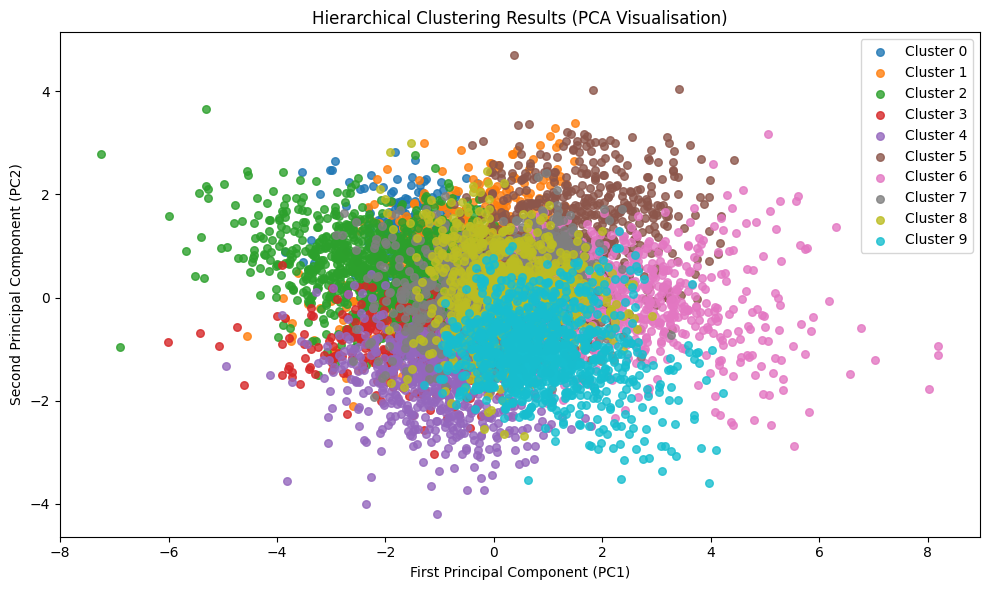

In [26]:
# Visualise hierarchical clusters using PCA
plt.figure(figsize=(10,6))

# Loop through each hierarchical cluster label
for i, cluster in enumerate(np.unique(hierarchical_labels)):

    # Select points belonging to the current cluster
    cluster_points = X_clustering_pca[hierarchical_labels == cluster]
    
    # Scatter plot of the points within the current cluster
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], color=colours[i % 10], label=f"Cluster {cluster}", s=30, alpha=0.8)

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("Hierarchical Clustering Results (PCA Visualisation)")
plt.legend()
plt.tight_layout()
plt.show()

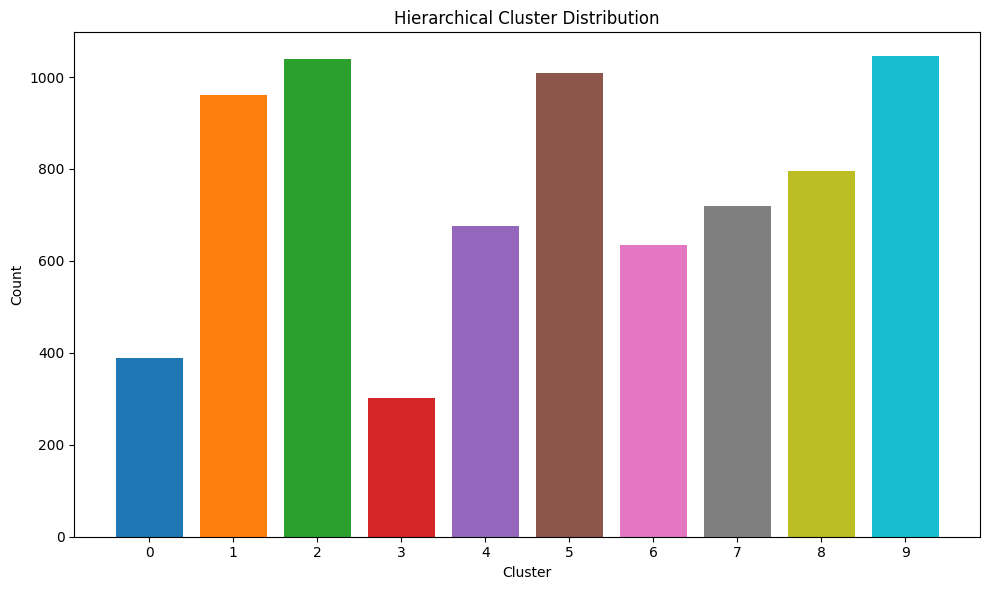

In [27]:
# Visualise hierarchical cluster distribution
plt.figure(figsize=(10,6))

# Bar chart showing number of points in each hierarchical cluster
plt.bar(counts_hierarchical.index, counts_hierarchical.values, color=colours[:len(counts_hierarchical)])
plt.xticks(counts_hierarchical.index)
plt.xlabel("Cluster")
plt.ylabel("Count")
plt.title("Hierarchical Cluster Distribution")
plt.tight_layout()
plt.show()

### **Comparing Clustering Methods**

In [28]:
# Compare k-means and Hierarchical clustering metrics
comparison_table = pd.DataFrame({
    "Method": ["K-means", "Hierarchical (Ward)"],
    "Number of Clusters (k)": [optimal_k_kmeans, optimal_k_hierarchical],
    "Silhouette Score": [sil_kmeans, sil_hc],
    "Calinski-Harabasz Score": [ch_kmeans, ch_hc],
    "Davies-Bouldin Score": [db_kmeans, db_hc]
}).round(3)

display(comparison_table)

,Method,Number of Clusters (k),Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-means,9,0.168,1235.825,1.435
1,Hierarchical (Ward),10,0.099,853.175,1.696


**Comparison of Clustering Methods**

The clustering results obtained using k-means and hierarchical clustering (Ward linkage) show that both methods produce a relatively low but comparable Silhouette score, which indicates similar overall level of cluster cohesion and separation in this high dimensional dataset.

K-means achieves higher values for both the Silhouette Score ($0.168$) and the Calinski–Harabasz Index ($1235.825$) compared to hierarchical clustering ($0.099$ and $853.175$ respectively). These results suggest that k-means clustering produces more compact clusters with greater separation between them. In addition, k-means achieves a lower Davies–Bouldin score ($1.435$) than hierarchical clustering ($1.696$), which indicates reduced average similarity between clusters.

Both clustering methods select a similar number of clusters with k-means selecting $k = 9$ and hierarchical clustering selecting $k = 10$. This consistency suggests that both approaches identify a comparable level of detail in the underlying structure of the data. Values of $k$ close to $10$ are possible given that the dataset is a random sample drawn from the MNIST dataset, which contains handwritten digits from $0$ to $9$. Although not all digit classes are guaranteed to be present.

Overall, k-means provides a more compact and better-separated clustering solution for this dataset, which is supported by all three internal validation metrics. Hierarchical clustering remains valuable for exploratory analysis as the dendrogram offers insight into the multi-level structure of the data and relationships between clusters. However, due to its superior clustering metrics and computational efficiency k-means is the preferred method for this dataset [9].

---

## **Classification**

Classification is a type of supervised learning where the target feature that is to be predicted is a categorical variable. The target feature also called the class can have two or more levels (categories), which may or may not be ordered. The goal of classification is to train a model using known input data and corresponding class labels so that is can assign the correct class to new unseen observations [10].

- The classification dataset is formed from a random sample of handwritten digit images taken from the MNIST dataset,
- Each row represents a single image and each column corresponds to a pixel intensity value,
- A class label is provided for each image, indicating the corresponding digit ($0–9$),
- The presence of labels makes this dataset suitable for supervised machine learning,
- Since the dataset is a random sample of the MNIST dataset, it may not contain all digit classes.

---

**Loading Classification Dataset**

In [29]:
# Load classification CSV file corresponding to student ID
df_classification = pd.read_csv("40360767_classification.csv")

print("Successfully Loaded Classification dataset")

Successfully Loaded Classification dataset


**Initial Inspection**

In [30]:
# Get basic information about the dataset
# Number of features (columns)
num_columns = df_classification.shape[1]

# Number of samples (rows)
num_rows = df_classification.shape[0]

# Investigating classification dataset
print("Shape of classification dataset: ", df_classification.shape)
print("Columns in classification dataset: ", df_classification.columns.tolist())
print("Number of columns in classification dataset: ", num_columns)
print("Number of rows in classification dataset: ", num_rows)

# Display first 5 rows in classification dataset
display(df_classification.head())

# Display summary statistics of classification dataset
print("Summary statistics of classification dataset:")
display(df_classification.describe())

Shape of classification dataset:  (5689, 13)
Columns in classification dataset:  ['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'label']
Number of columns in classification dataset:  13
Number of rows in classification dataset:  5689


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,label
0,-0.3627,1.5676,-1.3440,-0.0727,0.9812,0.7190,0.4366,2.3712,1.2120,2.3397,0.4795,-0.7945,4
1,2.0365,-1.7373,-1.7486,-1.5869,-2.2592,-3.9219,0.5864,0.3538,-2.6875,-0.5493,1.1799,0.2096,0
2,-1.3913,-1.0295,-2.6789,1.0551,-0.4573,0.6585,0.4690,3.4236,1.7178,1.7091,1.2410,-2.2236,2
3,5.2971,1.6318,1.3412,0.9118,0.5227,0.1569,3.4269,2.7287,-0.3768,1.5231,-2.6939,-0.4889,6
4,-4.8147,3.8358,1.5549,-1.4878,0.5833,1.0046,-3.5186,-1.7364,-0.1854,NaN,-1.6176,-0.9858,3


Summary statistics of classification dataset:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,label
count,5631.000000,5639.000000,5636.000000,5624.000000,5643.000000,5629.000000,5626.000000,5645.000000,5625.000000,5640.000000,5628.000000,5621.000000,5689.000000
mean,0.132918,-0.001390,0.136963,-0.107030,0.141360,0.225291,0.399138,0.951912,0.016701,0.315760,0.005112,-0.397406,3.589735
std,3.571855,1.977316,2.050057,2.158782,2.141853,2.159507,2.045182,4.195831,2.093899,2.064619,2.110477,1.904011,2.353904
min,-11.468700,-7.383100,-7.015100,-8.703000,-7.873900,-8.563900,-7.331500,-16.287500,-7.742600,-7.800900,-7.946400,-6.549400,0.000000
25%,-2.297750,-1.357750,-1.222500,-1.504275,-1.319300,-1.234800,-0.972900,-1.768200,-1.375300,-1.091700,-1.462650,-1.696300,2.000000
50%,-0.024400,0.025200,0.219950,-0.109650,0.128800,0.252500,0.424600,1.089300,-0.072700,0.323800,-0.061050,-0.481100,4.000000
75%,2.421050,1.374200,1.533450,1.322875,1.558100,1.699200,1.760975,3.736400,1.367900,1.720100,1.334150,0.860200,6.000000
max,12.971900,7.223100,7.547200,7.986700,9.523100,7.853400,8.275200,17.574700,8.705700,7.634000,9.492700,7.857200,8.000000


**Class Label Inspection**

In [31]:
# Print the number of unique class labels
print("Number of unique labels in classficiation dataset: \n", len(df_classification["label"].unique()))

# Print the sorted list of unique labels
print("Unique labels in classification dataset: ", np.sort(df_classification["label"].unique()))

print("Number of times each label appears in classification dataset: ")

# Count occurrences of each class label
label_counts = df_classification["label"].value_counts().sort_index().reset_index()

# Rename columns for clarity
label_counts.columns = ["label", "count"]

# Compute class percentages
label_counts["percentage"] = round(label_counts["count"] / num_rows, 2)

# Display class distribution table
display(label_counts)

# Convert label column to categorical type
df_classification["label"] = df_classification["label"].astype("category")

Number of unique labels in classficiation dataset: 
 9
Unique labels in classification dataset:  [0 1 2 3 4 5 6 7 8]
Number of times each label appears in classification dataset: 


,label,count,percentage
0,0,693,0.12
1,1,696,0.12
2,2,705,0.12
3,3,701,0.12
4,4,692,0.12
5,5,696,0.12
6,6,695,0.12
7,7,693,0.12
8,8,118,0.02


**Missing Value Analysis**

In [32]:
# Total number of missing values in the dataset
num_missing_values = df_classification.isnull().sum().sum()

# Total number of cells in the dataset
total_cells = df_classification.shape[0] * df_classification.shape[1]

print("Number of missing values in classification dataset: ", num_missing_values)
print("Percentage of missing values in classification dataset: ", num_missing_values / total_cells * 100)

# Number of rows containing at least one missing value
rows_with_missing = df_classification.isnull().any(axis=1).sum()

print("Number of rows with missing values in classification dataset: ", rows_with_missing)
print("Percentage of rows with missing values in classification dataset: ", rows_with_missing / num_rows * 100)

Number of missing values in classification dataset:  681
Percentage of missing values in classification dataset:  0.9208053328285355
Number of rows with missing values in classification dataset:  642
Percentage of rows with missing values in classification dataset:  11.284935841096853


**Missing Values per Feature**

In [33]:
# Number of missing values per column
missing_per_column = df_classification.isnull().sum()

# Create a summary dataframe (counts and percentages) and transpose so the features are columns in the dataframe
missing_per_column_df = pd.DataFrame({"Missing Count": missing_per_column, "Percentage Missing (%)": (missing_per_column / num_rows * 100)}).T

print("Missing values per column in classification dataset:")
display(missing_per_column_df)

Missing values per column in classification dataset:


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,label
Missing Count,58.000000,50.000000,53.000000,65.000000,46.000000,60.000000,63.0000,44.000000,64.000000,49.000000,61.000000,68.000000,0.0
Percentage Missing (%),1.019511,0.878889,0.931622,1.142556,0.808578,1.054667,1.1074,0.773422,1.124978,0.861311,1.072245,1.195289,0.0


**Missingness vs Class Labels**

In [34]:
# Create a flag indicating whether a row contains atleast one missing value
df_classification["missing_any"] = df_classification.isnull().any(axis=1)

# Cross-tabulate class labels against missingness indicator
ct = pd.crosstab(df_classification["label"], df_classification["missing_any"])

# Compute row-wise percentages
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Add percentage of rows with missing values per class
ct["% missing (True)"] = ct_pct.get(True, 0)

# Display the table
display(ct)

# Remove temporary helper column
df_classification = df_classification.drop(columns="missing_any")

missing_any,False,True,% missing (True)
label,,,
0,606,87,12.554113
1,615,81,11.637931
2,629,76,10.780142
3,610,91,12.981455
4,615,77,11.127168
5,611,85,12.212644
6,622,73,10.503597
7,632,61,8.802309
8,107,11,9.322034


**Missingness Pattern Analysis** [11]

In [35]:
# Convert non-missing values to 1 and missing values to 0
presence = df_classification.notna().astype(int)

# Add helper column for counting unique patterns
presence["count"] = 1

# Count frequency of each missingness pattern
pattern_counts = presence.groupby(df_classification.columns.tolist())["count"].sum().sort_values(ascending=False).reset_index()
display(pattern_counts)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,label,count
0,1,1,1,1,1,1,1,1,1,1,1,1,1,5047
1,1,1,1,1,1,1,1,1,1,1,1,0,1,65
2,1,1,1,1,1,1,1,1,0,1,1,1,1,56
3,1,1,1,0,1,1,1,1,1,1,1,1,1,56
4,1,1,1,1,1,1,1,1,1,1,0,1,1,54
5,1,1,1,1,1,1,0,1,1,1,1,1,1,54
6,0,1,1,1,1,1,1,1,1,1,1,1,1,53
7,1,1,1,1,1,0,1,1,1,1,1,1,1,51
8,1,1,0,1,1,1,1,1,1,1,1,1,1,48
9,1,1,1,1,1,1,1,1,1,0,1,1,1,46


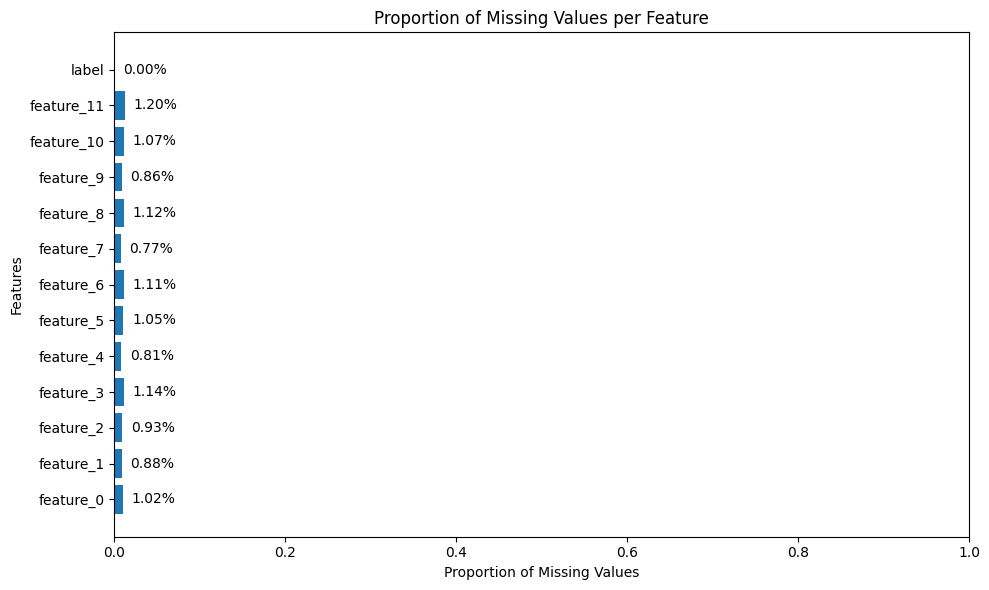

In [36]:
# Proportion of missing values per feature
prop = df_classification.isna().mean()

# Plot percentage of missing values per feature as a horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(prop.index, prop.values)
plt.xlabel("Proportion of Missing Values")
plt.ylabel("Features")
plt.title("Proportion of Missing Values per Feature")
plt.xlim(0, 1)

# Annotate bars with percentages
for b, v in enumerate(prop.values):
    plt.text(v + 0.01, b, f"{v*100:.2f}%", va="center")
plt.tight_layout()
plt.show()

**Missingness Map Visualisation** [11]

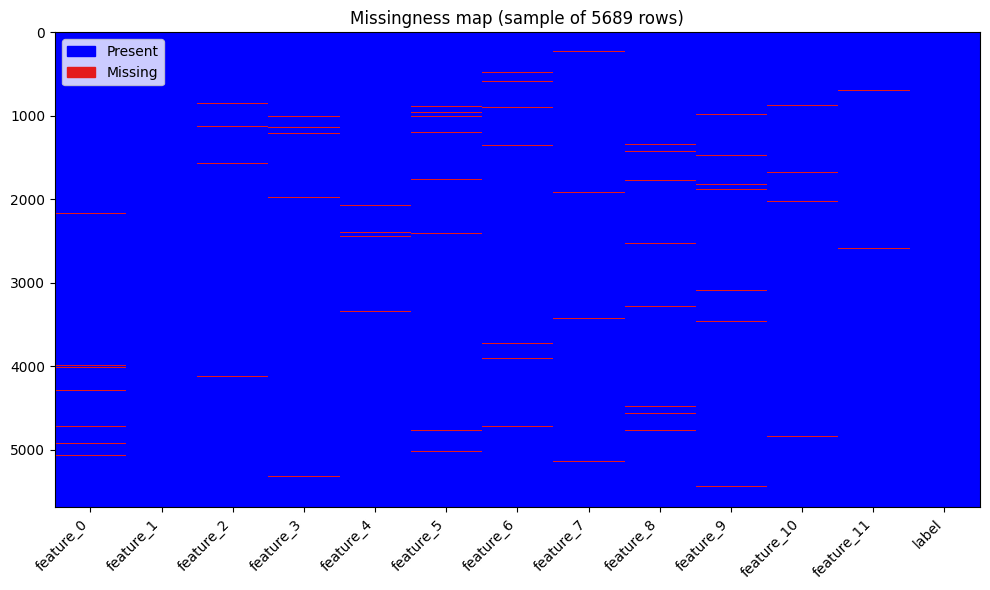

In [37]:
# Number of rows to display
n_show = len(df_classification)

# Randomly sample rows (without replacement)
rows = rng.choice(df_classification.index, size=n_show, replace=False)

# Create binary missingness mask (0 = present, 1 = missing)
mask = df_classification.loc[rows].isna().astype(int).to_numpy()

# Define colourmap: blue = present, red = missing
cmap = ListedColormap(["blue", "#e41a1c"])

plt.figure(figsize=(10, 6))
plt.imshow(mask, aspect="auto", interpolation="nearest", cmap=cmap)

# Feature names on x-axis
plt.xticks(ticks=range(len(df_classification.columns)), labels=df_classification.columns, rotation=45, ha="right")

plt.title(f"Missingness map (sample of {n_show} rows)")

# Legend
present_patch = mpatches.Patch(color="blue", label="Present")
missing_patch = mpatches.Patch(color="#e41a1c", label="Missing")
plt.legend(handles=[present_patch, missing_patch], loc="upper left")

plt.tight_layout()
plt.show()

**MCAR Test Using R Package `naniar`** [12]

In [38]:
# Import naniar package from R
naniar = importr("naniar")

# Enable conversion between pandas DataFrames and R dataframes
converter = robjects.default_converter + pandas2ri.converter

# Run MCAR test on feature columns only (exclude label)
with localconverter(converter):
    result_df = naniar.mcar_test(df_classification.drop(columns=["label"]))
    result_df = pd.DataFrame(result_df)

# Display MCAR test results
display(result_df)

,statistic,df,p.value,missing.patterns
1,474.225429,442.0,0.139876,44


### **MCAR Analysis** 

Missing Completely at Random (MCAR) refers to a situation where the likelihood of a value being missing is independent of both observed and unobserved data. In other words the missing values occur in no systematic pattern, which makes them truly random. If the data is MCAR then simple techniques such as complete-case analysis or mean or median imputation can yield unbiased results [13].

##### **Overall Missingness**

- Total number of missing values: $681$  
- Percentage of missing values: $0.92\%$  
- Number of rows with at least one missing value: $642$  
- Percentage of affected rows: $11.28\%$

Although approximately $11\%$ of rows contain missing values the overall proportion of missing data is very low, which indicates that missingness is sparse and unlikely to be systematic.

##### Missingness Across Features

The percentage of missing values is consistently low and evenly distributed across all input features:

- Minimum missing percentage: **$0.77\%$ (feature_7)**
- Maximum missing percentage: **$1.20\%$ (feature_11)**

No single feature exhibits a disproportionately high level of missingness. This uniform distribution supports the assumption that the missing values occur randomly rather than being driven by specific variables.

##### **Relationship Between Missingness and the Target Variable**

An analysis of missingness by class label shows that:

- All classes contain both complete and incomplete observations
- The proportion of missing values is similar across all classes
- No class is over-represented among rows with missing data

This indicates that missingness is independent of the target variable, which rules out label-dependent missingness mechanisms such as MAR or MNAR.

##### **Missingness Patterns**

- A total of $44$ distinct missingness patterns were identified
- The presence of many small patterns suggests random scatter rather than structured or systematic missingness

Structured missingness would be expected under MAR or MNAR but this is not observed here.

##### **Statistical Test for MCAR (naniar)**

The MCAR test was performed using the `naniar` R package, which gave the following results:

- **Test statistic:** $474.23$  
- **Degrees of freedom:** $442$  
- **p-value:** $0.1399 $ 

$H_0$: Data is missing completely at random (MCAR)

$H_1$: Data is not missing completely at random

Since the p-value is greater than $0.05$ the test is not significant at the $5\%$ level. There is insufficient evidence to reject the null hypothesis in favour of the alternative. There is not enough evidence to suggest that the data is not missing completely at random.

##### **Conclusion**

The missing data displays the following characteristics:
- A low overall proportion of missing values
- A uniform distribution of missing values across features
- Independence between missingness and the class label
- No evidence of structured or systematic missingness patterns
- A non-significant result from the MCAR statistical test

These findings indicate that the missing data in this dataset is classified as MCAR (Missing Completely At Random).

##### **Implications for Data Preprocessing**

- Simple imputation techniques such as mean or median can be applied without introducing systematic distortion since the probability of missingness is independent of both observed feature values and the class label [13].
- Since missing values occur randomly across observations and class labels there is no specific class or feature range that is disproportionately affected. This prevents the introduction of systematic bias during imputation and preserves the representativeness of the dataset [13].

---

**Choice of Imputation Method** [14]

Before applying simple imputation to handle missing values it is important to determine whether mean or median imputation is more appropriate. This decision depends on whether the feature distributions are approximately normally distributed or exhibit skewness.

- **Mean imputation** is suitable when data follows a normal (symmetric) distribution.
- **Median imputation** is more robust when distributions are skewed or contain outliers.

To assess normality each feature is examined using:
- **Histograms with a fitted normal distribution**
- **Q–Q (quantile–quantile) plots**
- **Numerical skewness values**

---

**Distribution checking with normal fit**

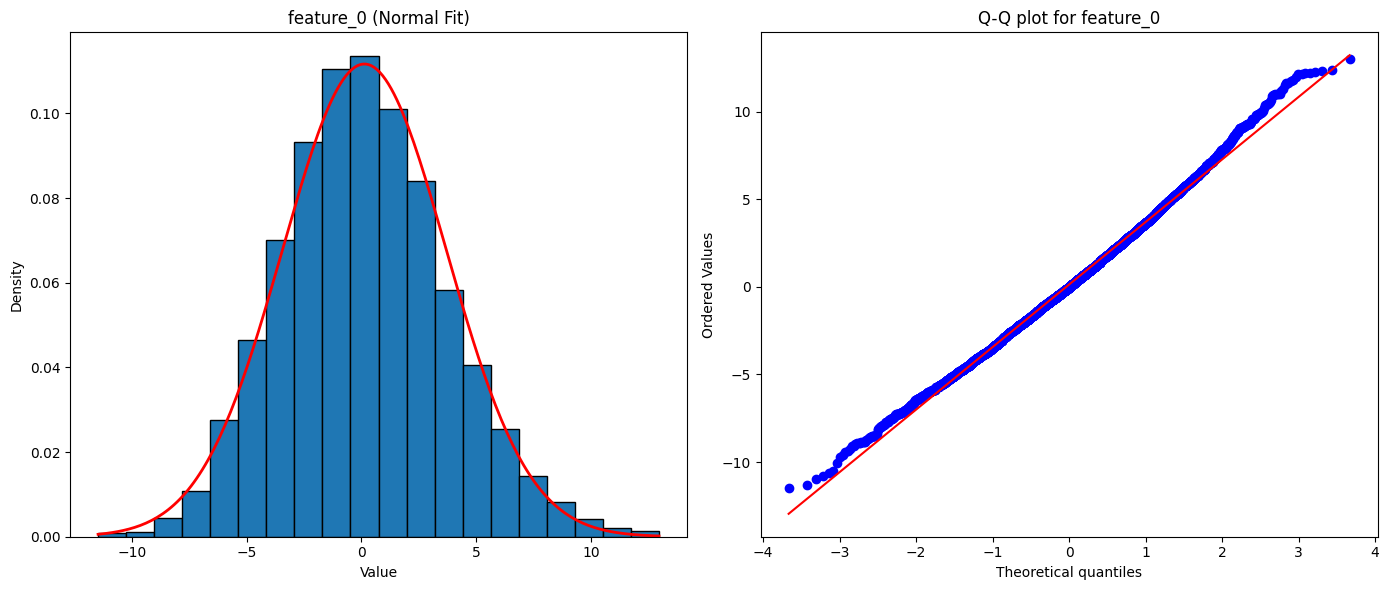

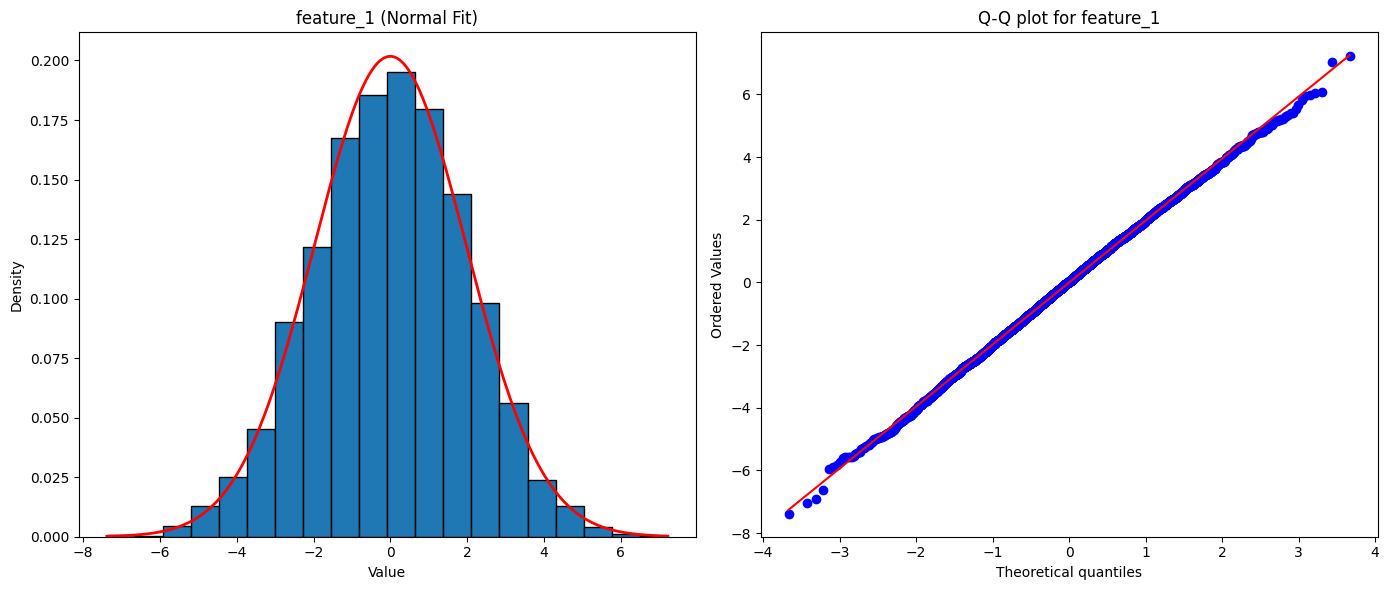

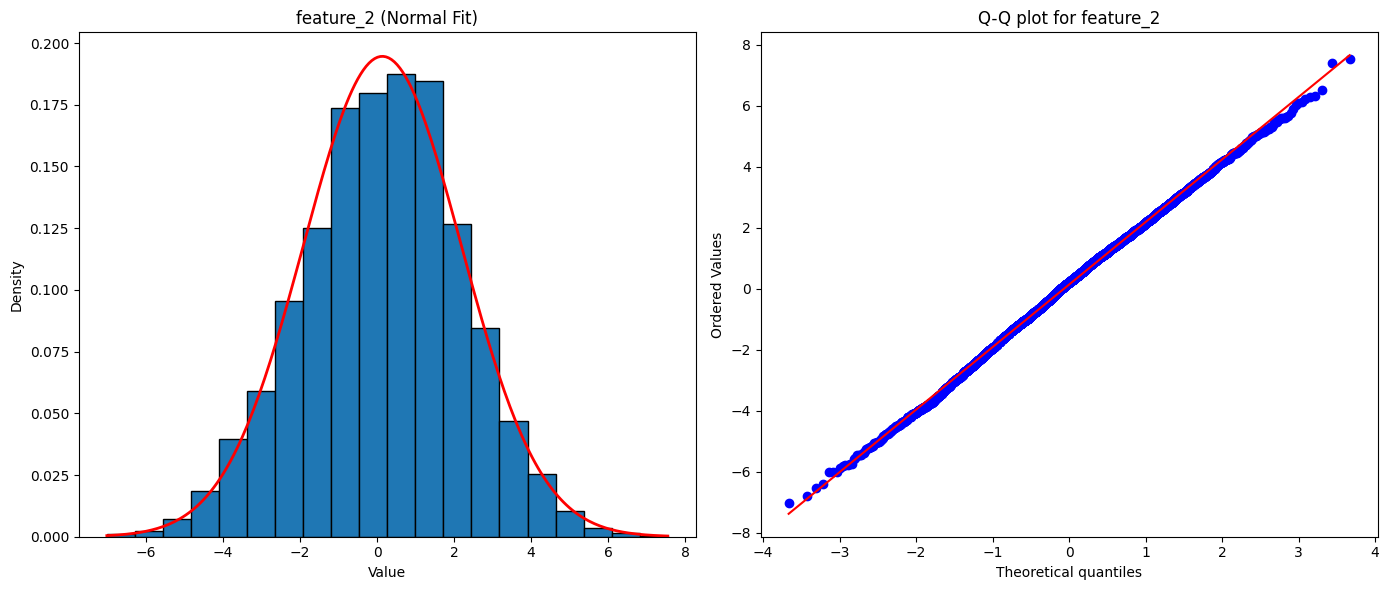

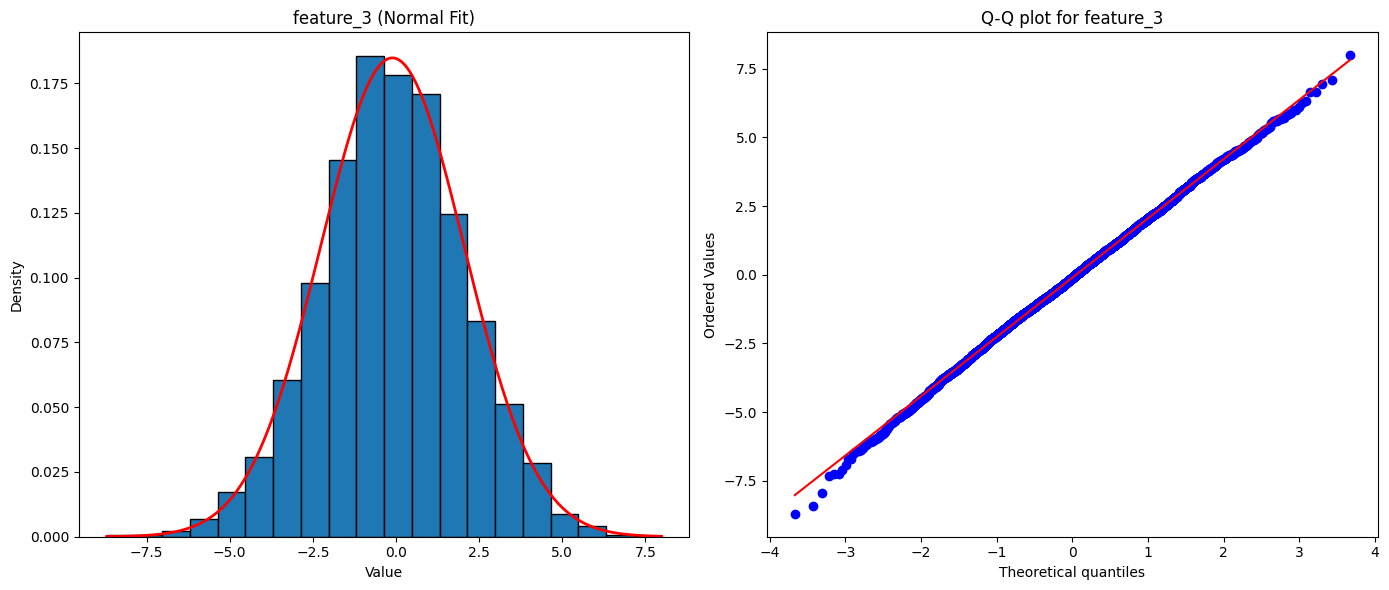

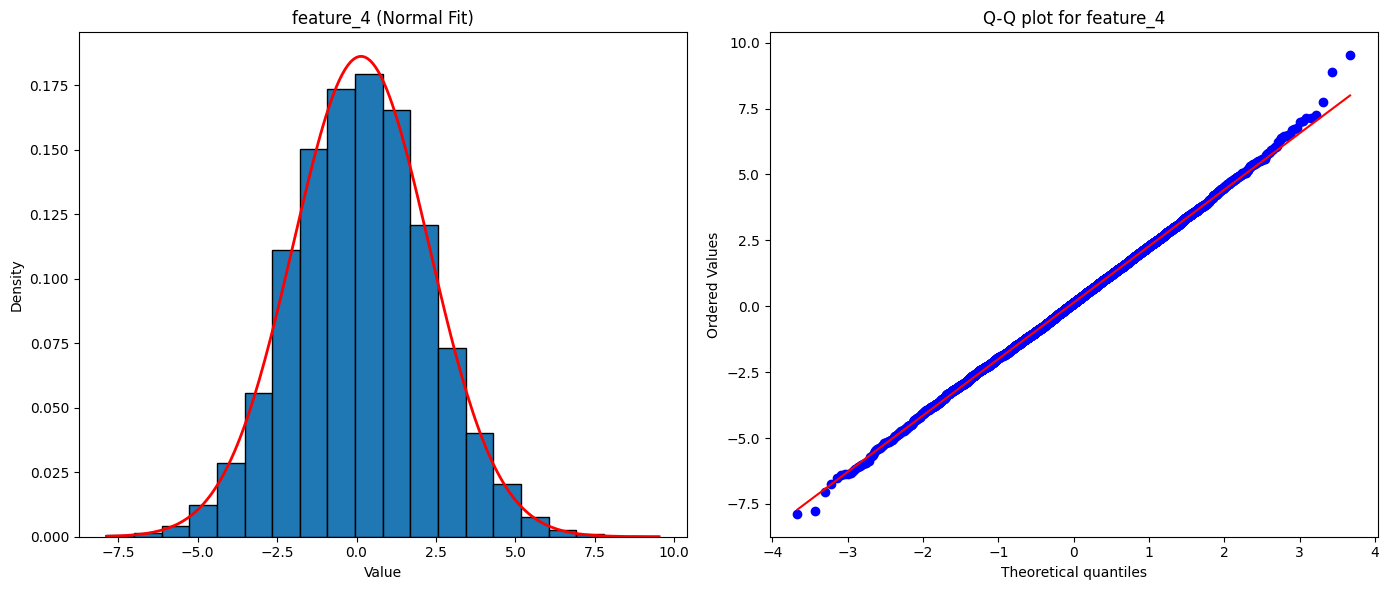

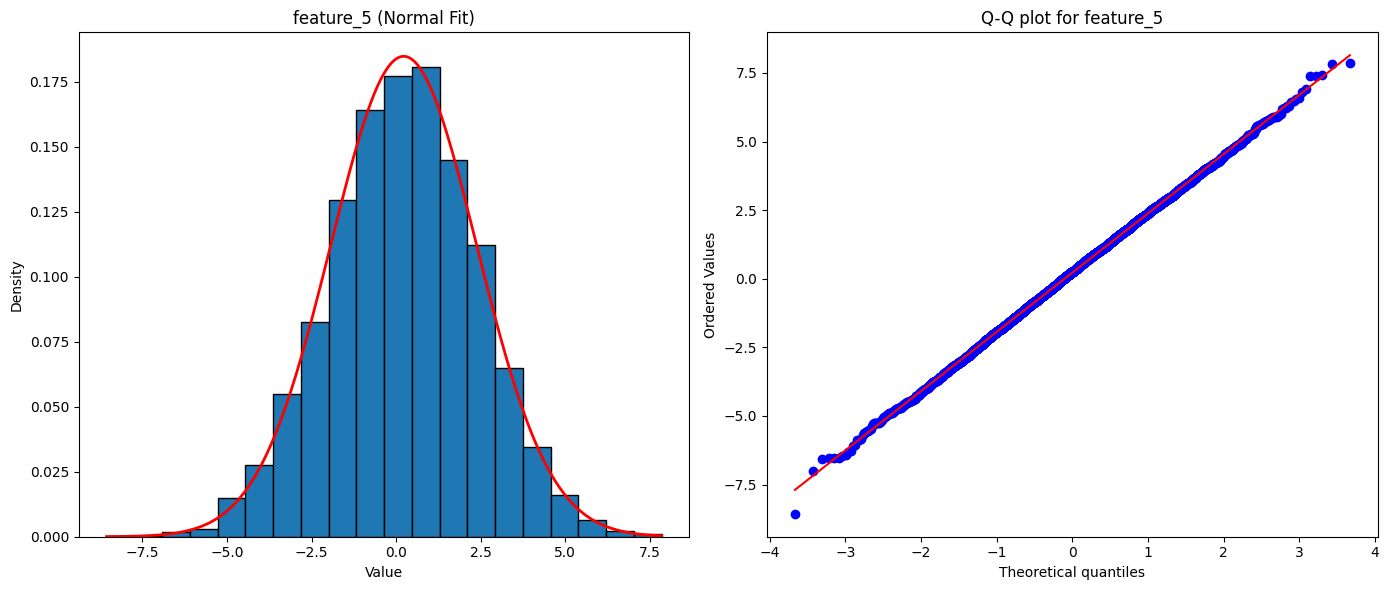

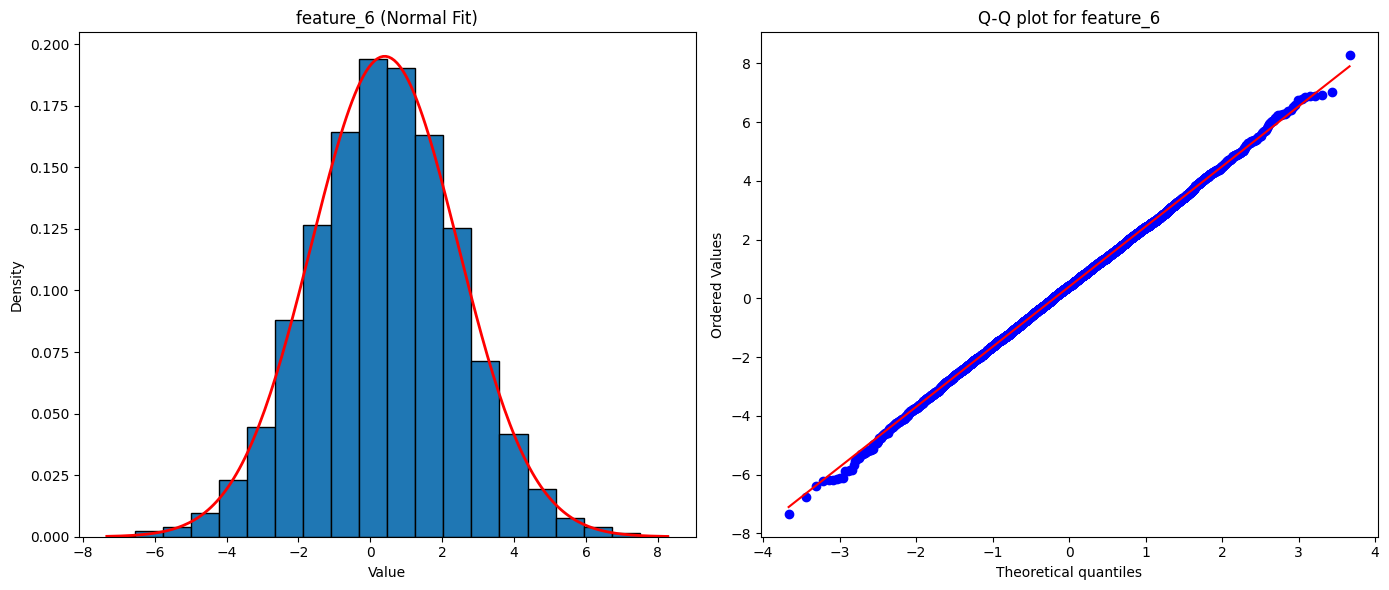

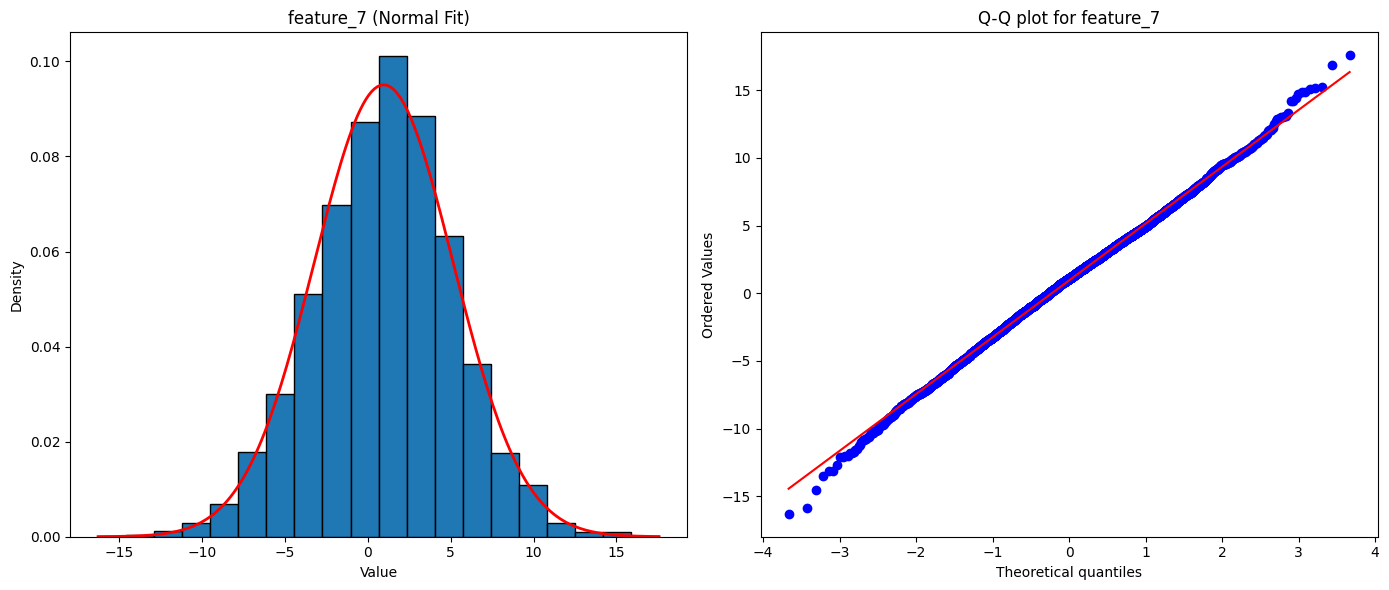

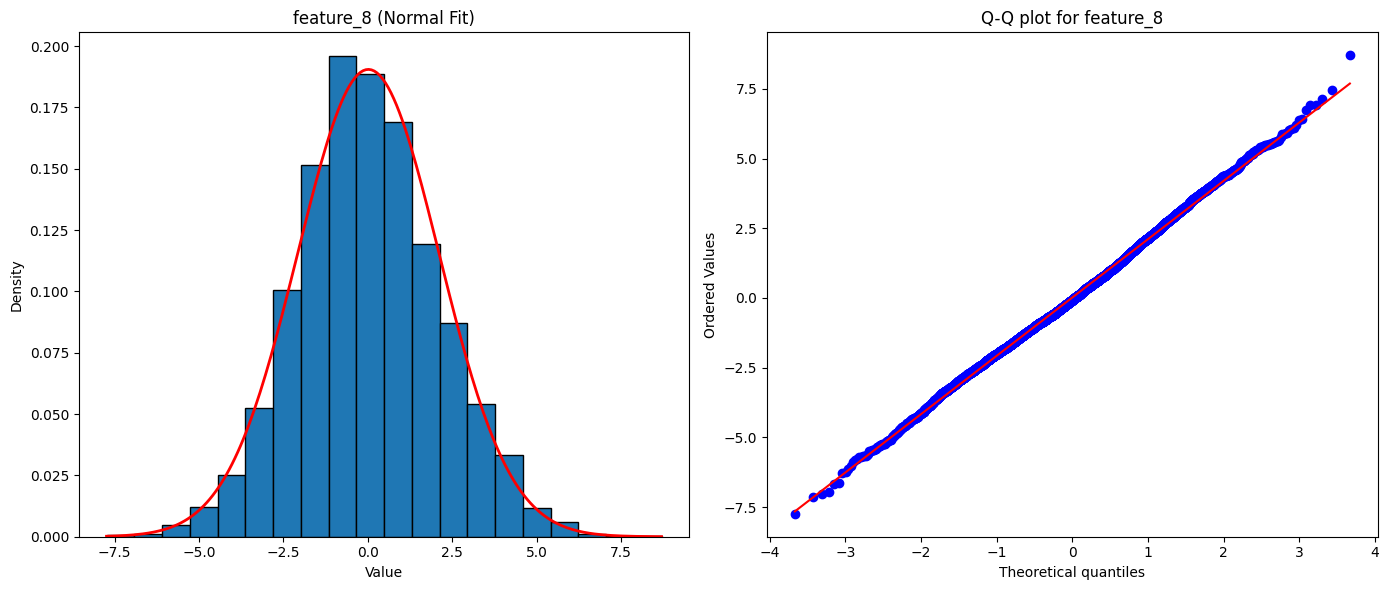

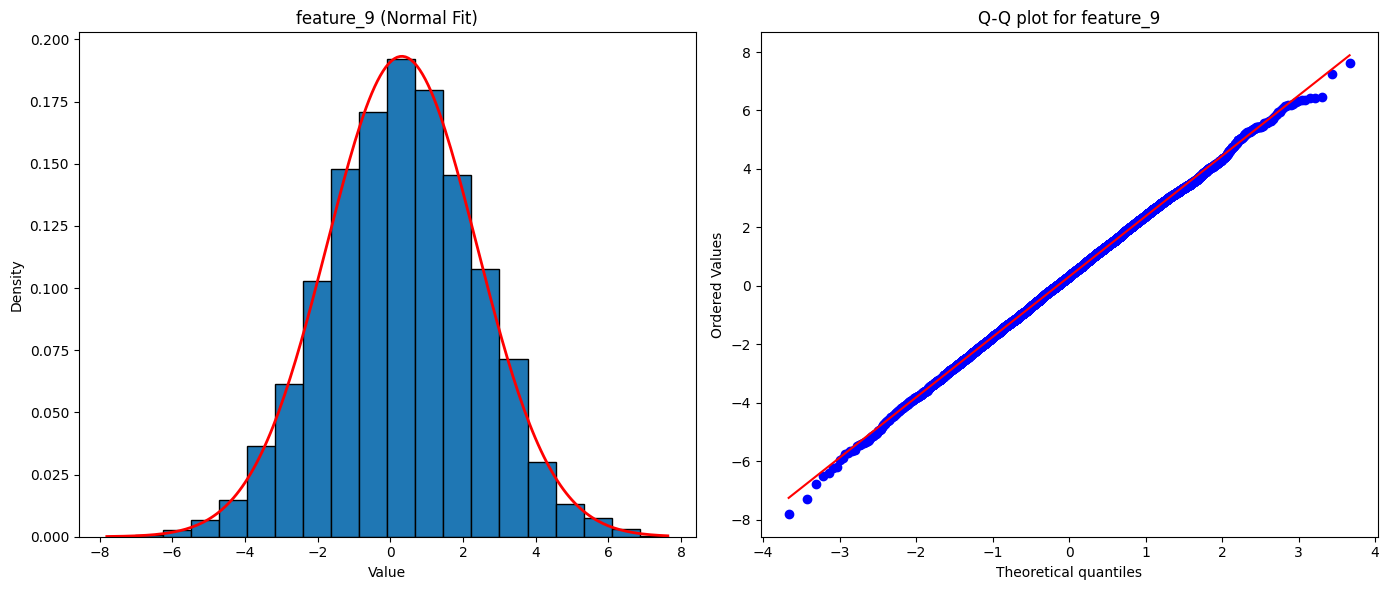

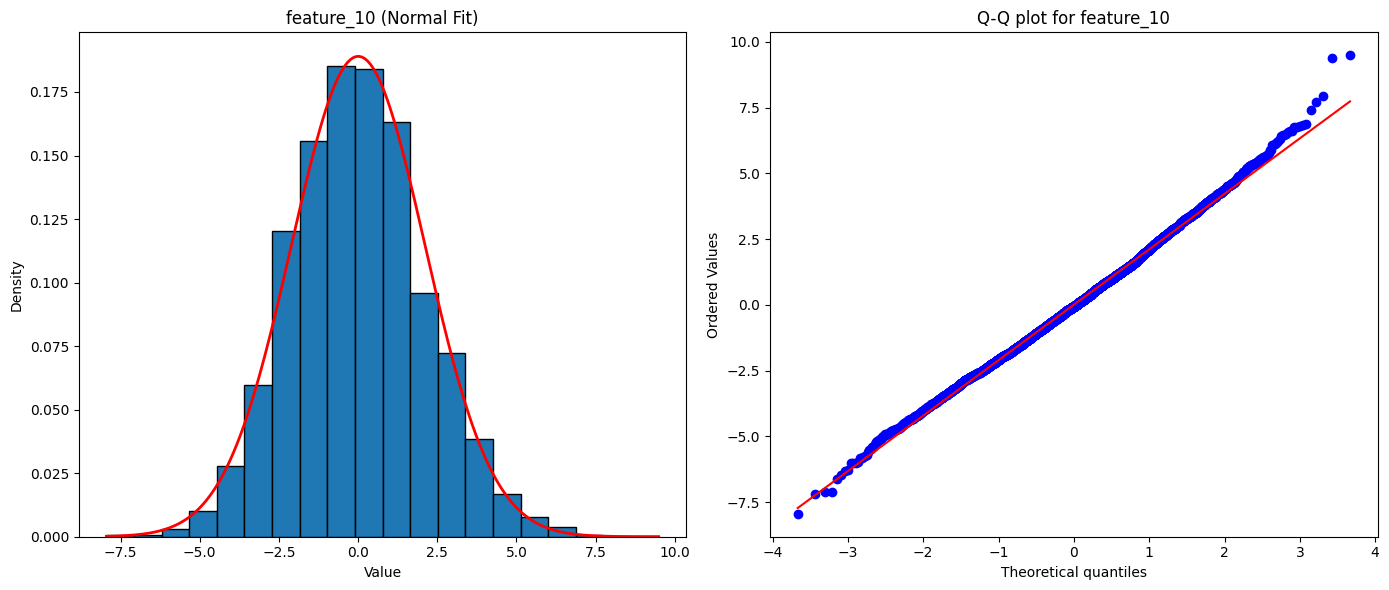

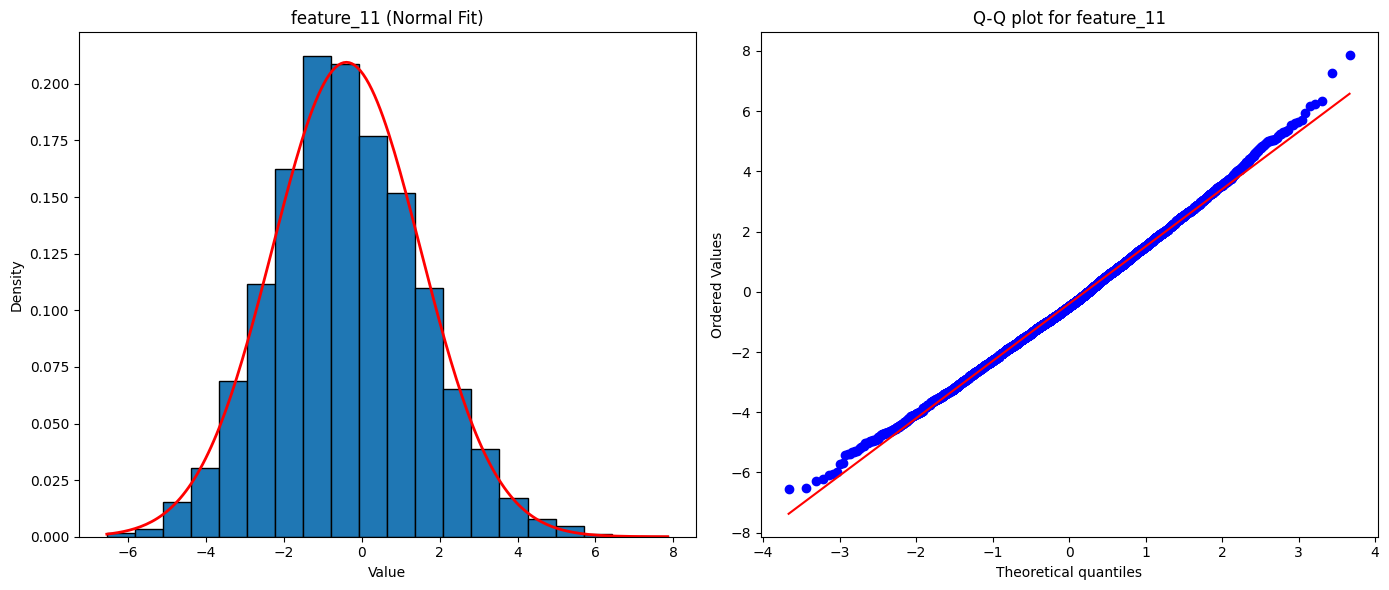

In [39]:
# Exclude the label column
columns = df_classification.drop(columns="label")

# Loop through each feature
for col in columns:

    # Remove missing values for distribution analysis
    data = df_classification[col].dropna()

    # Estimate parameters of the normal distribution
    mu = data.mean()
    sigma = data.std()
    
    # Create a subfigure with 1 row and 2 columns
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Plot histogram of feature values (density scaled)
    count, bins, _ = axes[0].hist(data, bins=20, edgecolor="black", density=True)
    
    # Generate x values and corresponding normal PDF
    x = np.linspace(bins.min(), bins.max(), 200)
    y = norm.pdf(x, mu, sigma)

    # Overlay normal distribution curve
    axes[0].plot(x, y, linewidth=2, color="red")

    axes[0].set_title(f"{col} (Normal Fit)")
    axes[0].set_xlabel("Value")
    axes[0].set_ylabel("Density")

    # Generate a Q–Q plot comparing the feature distribution to a theoretical normal distribution
    stats.probplot(df_classification[col].dropna(), dist="norm", plot=axes[1])
    
    axes[1].set_title(f"Q-Q plot for {col}")
    
    plt.tight_layout()
    plt.show()

**Skewness Analysis of Features**

In [40]:
# Calculate the skewness of each feature (excluding the label)
skew = df_classification.drop(columns=["label"]).skew()

# Print skewness of the features
print(skew)
print("Max skew:", max(skew))
print("Min skew:", min(skew))

feature_0     0.234233
feature_1    -0.070013
feature_2    -0.092649
feature_3    -0.061345
feature_4     0.056943
feature_5    -0.036261
feature_6    -0.018556
feature_7    -0.074371
feature_8     0.114729
feature_9    -0.046332
feature_10    0.186617
feature_11    0.181914
dtype: float64
Max skew: 0.23423293158014002
Min skew: -0.09264864435784534


##### **Visual Assessment of Normality**

The histograms with overlaid normal density curves and the Q–Q plots show that:

- Most features roughly follow a bell-shaped normal distribution
- However, there are noticeable deviations from perfect normality particularly in the tails
- Several Q–Q plots display slight curvature at the extremes. which indicates mild skewness or heavier tails than expected under a normal distribution

These visual diagnostics suggest that while the data is not heavily skewed it does not strictly satisfy the assumption of normality.

##### **Skewness Analysis**

All skewness values fall within the range $−0.093$ to $+0.234$, which indicates low to mild skewness across the features. While this suggests that the distributions are reasonably symmetric, none of the features are perfectly normal.

##### **Imputation Method Decision**

Considering that:
- The visual diagnostics show slight deviations from normality,
- The skewness values indicate slight asymmetry,
- Median imputation is more robust to outliers and non-normal distributions,

we choose median imputation as the preferred strategy for completing the dataset.

This ensures that the imputation minimally distorts the data while maintaining its overall structure and representativeness.

---

**Splitting Dataset into Training, Validation and Test Sets**

In [41]:
# Separate features and target variable
X = df_classification.drop(columns=["label"])
y = df_classification["label"]

In [42]:
# Setting test and validation set sizes
test_size = 0.1
val_size = test_size / (1 - test_size)

# First split: training + validation vs test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)

# Second split: training vs validation
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=val_size, stratify=y_temp, random_state=seed)

# Display dataset split sizes
print(f"Training set: {X_train.shape} samples - {X_train.shape[0] / len(X) * 100:.2f}%")
print(f"Validation set: {X_val.shape} samples - {X_val.shape[0] / len(X) * 100:.2f}%")
print(f"Test set: {X_test.shape} samples - {X_test.shape[0] / len(X) * 100:.2f}%")

Training set: (4551, 12) samples - 80.00%
Validation set: (569, 12) samples - 10.00%
Test set: (569, 12) samples - 10.00%


**Median Simple Imputation**

We fill missing values after splitting the dataset to avoid data leakage. Imputing before splitting allows information from the validation or test sets to influence the training data, which gives the model access to data it would not have in practice. By splitting first and then imputing using only the medians of the training data we ensure that the training medians are apllied to missing values in the training, validation and test sets. This simulates the conditions under how the model would be used in real world predictions [15]. 

In [43]:
# Initialise simple imputer using the median strategy
imputer = SimpleImputer(strategy='median')

# Fit only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply same transformation to validation and test data
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

In [44]:
# Convert back to DataFrames
X_train = pd.DataFrame(X_train_imputed, columns=X.columns, index=X_train.index)
X_val   = pd.DataFrame(X_val_imputed,   columns=X.columns, index=X_val.index)
X_test  = pd.DataFrame(X_test_imputed,  columns=X.columns, index=X_test.index)

In [45]:
# Check missing values
print("Numbr of missing values in training set:", X_train.isnull().sum().sum())
print("Numbr of missing values in validation set:", X_val.isnull().sum().sum())
print("Numbr of missing values in test set:", X_test.isnull().sum().sum())

Numbr of missing values in training set: 0
Numbr of missing values in validation set: 0
Numbr of missing values in test set: 0


In [46]:
# Display dataset split sizes
print(f"Training set: {X_train.shape} samples - {X_train.shape[0] / len(X) * 100:.2f}%")
print(f"Validation set: {X_val.shape} samples - {X_val.shape[0] / len(X) * 100:.2f}%")
print(f"Test set: {X_test.shape} samples - {X_test.shape[0] / len(X) * 100:.2f}%")

Training set: (4551, 12) samples - 80.00%
Validation set: (569, 12) samples - 10.00%
Test set: (569, 12) samples - 10.00%


**Class Distribution Across Splits**

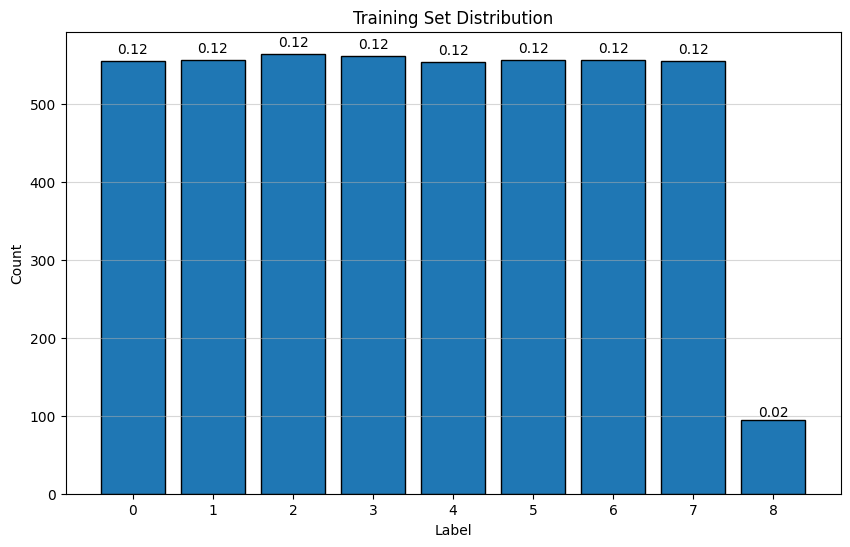

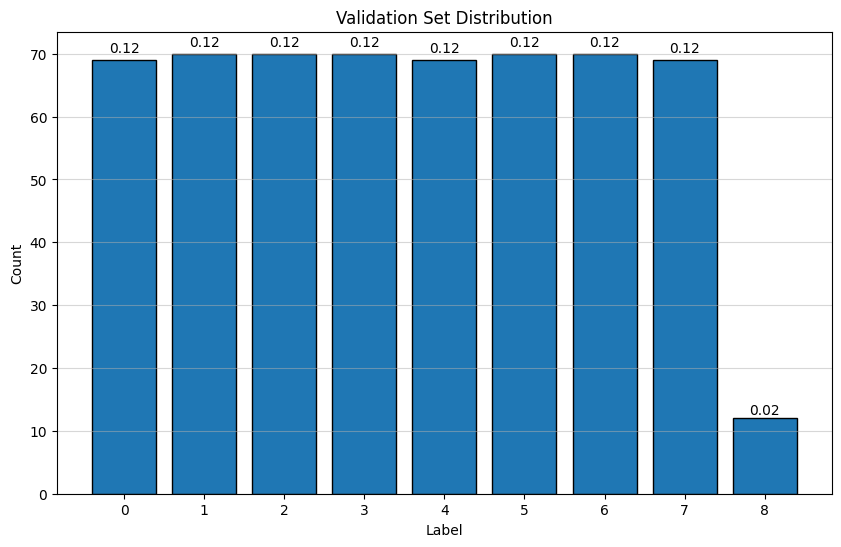

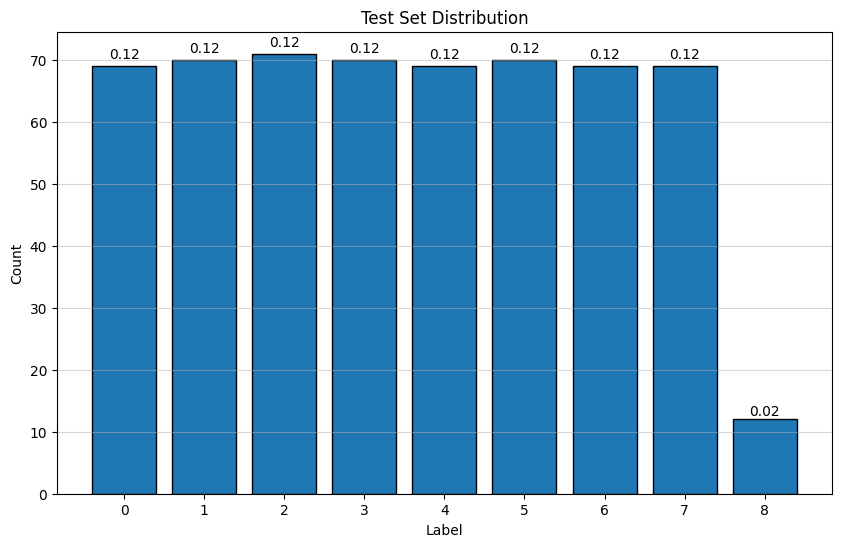

In [47]:
# Plotting the spilt of data for each feature across the spilts
# Loop over each dataset split
for data, title in [(y_train, "Training"), (y_val, "Validation"), (y_test, "Test")]:
    
    plt.figure(figsize=(10, 6))

    # Count how many samples belong to each class label and sort by label
    counts = data.value_counts().sort_index()

    # Plot a bar chart of counts per class
    plt.bar(counts.index, counts.values, edgecolor="black")
    
    # Total number of samples in the current split
    total_in_spilt = sum(counts.values)

    # Annotate each bar with the proportion of samples for that class
    for i, count in enumerate(counts.values):

        # Display proportion as a decimal
        plt.text(i, count * 1.01, str(round(count / total_in_spilt, 2)), ha="center", va="bottom")

    # Set x-axis ticks to the class labels
    plt.xticks(counts.index)

    plt.xlabel("Label")
    plt.ylabel("Count")
    plt.title(f"{title} Set Distribution")
    plt.grid(True, alpha=0.5, axis='y')
    plt.show()

**PCA Projection of Dataset Splits**

In [48]:
# Transform training, validation and test sets using PCA
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

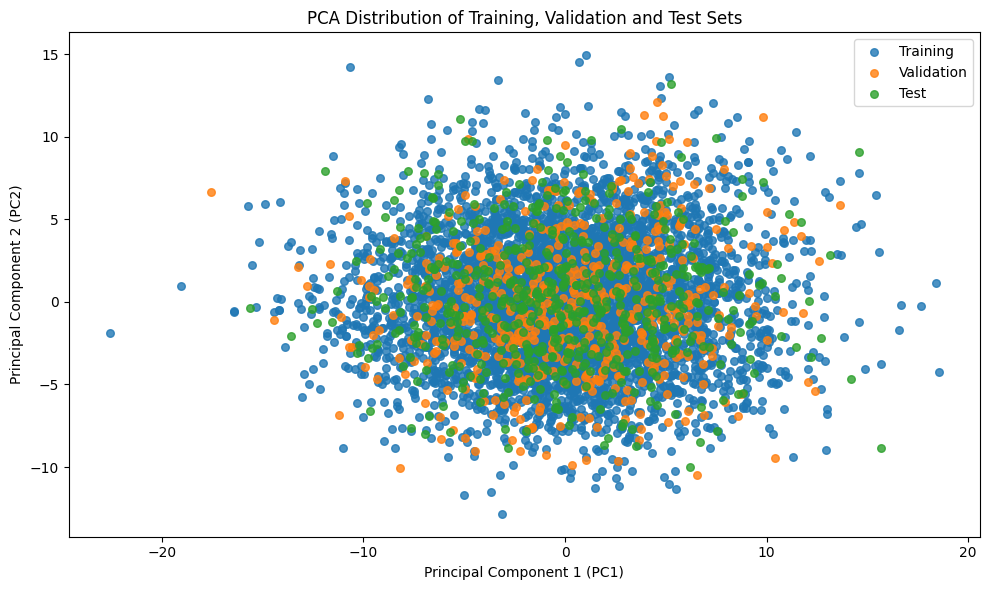

In [49]:
# Create a dictionary linking dataset splits to their PCA transformed data and a plotting colour
datasets = {"Training": (X_train_pca, colours[0]), "Validation": (X_val_pca, colours[1]), "Test": (X_test_pca, colours[2])}

# Plot PCA distributions
plt.figure(figsize=(10, 6))

for name, (data, colour) in datasets.items():

    # Scatter plot of PC1 vs PC2
    plt.scatter(data[:, 0], data[:, 1], label=name, color=colour, alpha=0.8, s=30)

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("PCA Distribution of Training, Validation and Test Sets")
plt.legend()
plt.tight_layout()
plt.show()

##### **Choice of Train–Validation–Test Split**

The dataset was divided into training, validation and test sets using an 80–10–10 split.

- **Training set ($80\%$)**  
  Used to fit the model parameters and learn patterns from the data.

- **Validation set ($10\%$)**  
  Used for model selection and hyperparameter tuning, which allows performance to be evaluated during development without biasing the final results.

- **Test set ($10\%$)**  
  Not used during the training and tuning process and used only once to provide an unbiased estimate of the final model’s generalisation performance.

---

##### **Reasoning for the $80–10–10$ Split**

This split was chosen to balance the competing objectives of model learning, tuning, and fair evaluation:

- Allocating 80% of the data to training ensures the model has sufficient information to learn stable and representative patterns.
- A 10% validation set provides enough data to tune hyperparameters and compare models without leaking information from the test set.
- A 10% test set ensures that the final performance metrics reflect how the model would perform on unseen data.

The $80–10–10$ split balances the need for adequate training data with sufficient validation and test sets for robust hyperparameter tuning and model evaluation [16].

##### **Additional Considerations**

- The split was performed using stratification, which ensures that the class proportions were preserved across all subsets.
- This helps prevent class imbalance from influencing model evaluation and ensures fair performance comparison.

---

**Save Splits to CSV Files**

In [50]:
# Save training data
training_df = X_train.copy()
training_df["label"] = y_train.values
training_df.to_csv("training.csv", index=False)

# Save validation data
validation_df = X_val.copy()
validation_df["label"] = y_val.values
validation_df.to_csv("validation.csv", index=False)

# Save test data
test_df = X_test.copy()
test_df["label"] = y_test.values
test_df.to_csv("testing.csv", index=False)

**Data Preprocessing**

In [51]:
# Scale the different datasets
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [52]:
# Apply Principal Component Analysis (PCA) to reduce dimensionality while retaining 95% of the total variance
pca2 = PCA(n_components=0.95, svd_solver="full", random_state=seed)

In [53]:
# Apply PCA to the different scaled datasets
X_train_scaled_pca = pca2.fit_transform(X_train_scaled)
X_val_scaled_pca = pca2.transform(X_val_scaled)
X_test_scaled_pca = pca2.transform(X_test_scaled)

**Baseline Classifier (Majority Class Classifier)** 

A baseline classifier is a simple model used to predict outcomes and serves as a starting point for analysis. It allows us to evaluate the performance of more complex models and understand the contribution of additional features. One common approach is the majority class classifier, which always predicts the most common class in the data. This provides a straightforward benchmark for comparison [17].

Information on DummyClassifier [18].

In [54]:
# Initialise DummyClassifier to always predict the most frequent class
clf = DummyClassifier(strategy="most_frequent")

# Fit to training labels (features X can be anything; not used)
clf.fit(X_train_scaled, y_train)

# Make predictions
y_train_pred = clf.predict(X_train_scaled)
y_val_pred   = clf.predict(X_val_scaled)
y_test_pred  = clf.predict(X_test_scaled)

# Compute accuracy
base_train_acc = accuracy_score(y_train, y_train_pred)
base_val_acc   = accuracy_score(y_val, y_val_pred)
base_test_acc  = accuracy_score(y_test, y_test_pred)

# Compute F1 score
base_train_f1 = f1_score(y_train, y_train_pred, average="macro")
base_val_f1   = f1_score(y_val, y_val_pred, average="macro")
base_test_f1  = f1_score(y_test, y_test_pred, average="macro")

print("Majority class:", clf.classes_[clf.class_prior_.argmax()])
print(f"Baseline Train accuracy: {base_train_acc:.4f}")
print(f"Baseline Train F1 score: {base_train_f1:.4f}")
print(f"Baseline Validation accuracy: {base_val_acc:.4f}")
print(f"Baseline Validation F1 score: {base_val_f1:.4f}")
print(f"Baseline Test accuracy: {base_test_acc:.4f}")
print(f"Baseline Test F1 score: {base_test_f1:.4f}")

Majority class: 2
Baseline Train accuracy: 0.1239
Baseline Train F1 score: 0.0245
Baseline Validation accuracy: 0.1230
Baseline Validation F1 score: 0.0243
Baseline Test accuracy: 0.1248
Baseline Test F1 score: 0.0247


**Model Train and Tune Parameters Using Validation Set**

In [55]:
def train_and_tune_classifier(model_class, param_grid, X_t, y_t, X_v, y_v, X_tt, y_tt):
    
    # Generate all combinations of hyperparameters
    grid = ParameterGrid(param_grid)
    
    # Declaring variables
    best_val_acc = 0
    best_model = None
    best_params = None
    
    # Loop through every combination of hyperparameters
    for params in grid:

        # If the classifier has a random_state parameter, set it for reproducibility
        if "random_state" in model_class().get_params():
            model = model_class(**params, random_state=seed)
        else:
            model = model_class(**params)

        # Train the model on the training set
        model.fit(X_t, y_t)

        # Evaluate on the validation set
        val_acc = accuracy_score(y_val, model.predict(X_v))
        
        # Update best model if validation accuracy improves
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_model = model
            best_params = params
    
    # Evaluate the best model on the test set
    y_pred = best_model.predict(X_tt)
    test_acc = accuracy_score(y_tt, y_pred)
    test_f1 = f1_score(y_tt, y_pred, average="macro")
    
    # Return results in a dictionary
    result = {"best_model": best_model, "best_params": best_params, "validation_accuracy": best_val_acc, "test_accuracy": test_acc, "f1_score": test_f1}
    
    return result

In [56]:
# Results dictionary
results = {}

**Classification Tree Classifier**

A decision tree classifier predicts an observation's class by recursively splitting the feature space into regions that are increasingly homogeneous with respect to the target variable. Each split is choosen to maximise the separation between classes and the final prediction for a region is determined by the majority class in the terminal noode [19].

Advantages:

- Relatively fast compared to other classification methods [20],
- Easy to interpet,
- Robust to outliers.

Disadvantages:

- Decision Trees are prone to overfitting,
- Unstable to changes in the data,
- Computationally expensive on large datasets [21].

---

In [57]:
# Define hyperparameter grid for Decision Tree
dt_params = {"max_depth": [3, 5, 7, 10, 15, 20, None], "min_samples_split": [2, 5, 10, 20], "min_samples_leaf": [1, 2, 4, 8]}

**Without PCA**

In [58]:
# Train Decision Tree on scaled features
results["Classification Tree"] = train_and_tune_classifier(DecisionTreeClassifier, dt_params, X_train, y_train, X_val, y_val, X_test, y_test)

**With PCA**

In [59]:
# Train Decision Tree on PCA transformed scaled features
results["Classification Tree PCA"] = train_and_tune_classifier(DecisionTreeClassifier, dt_params, X_train_scaled_pca, y_train, X_val_scaled_pca, y_val, X_test_scaled_pca, y_test)

**Naïve Bayes Classifier**

Naïve Bayes classifiers make predictions by estimating the likelihood of each feature value for every class and then combining these likelihoods via Bayes' rule. For continuous features we apply the Gaussian Naïve Bayes variant. This approach assumes that within each class each feature follows a bell-shaped (Guassian) distribution. Even if the data roughly follows this shape Guassian Naïve Bayes remains fast, simple and frequently competitive.

Bayes' Rule:

Bayes' rule combines prior knowledge about the classes with evidence from the observed features:

$$
\Pr(\text{Class} \mid Features)
=
\frac{
\Pr(Features \mid \text{Class}) \, \Pr(\text{Class})
}{
\Pr(Features)
}.
$$

- $\Pr(\text{Class} \mid \text{Features})$ - *posterior*: the probability of the class after observing the data.

- $\Pr(\text{Features} \mid \text{Class})$ - *likelihood*: how well the class explains the observed features.

- $\Pr(\text{Class})$ - *prior*: how common the class is before considering any features.

- $\Pr(\text{Features})$ - a normalising constant ensuring the posterior probabilities sum to 1.

The Naïve Bayes classifier assigns an observation to the class with the highest posterior probability [19].

Advantages:

- Fast to train and classify [19],
- Suitable for solving multiclass prediction problems,
- If the assumption of independent features holds true it can perform better than other models and requires much less training data.

Disadvantages:

- Assumes that all features are independent, which rarely happens in real life.
- The algorithm faces a zero frequency problem where it assigns zero probability to a categorical variable whose category in the test data set isn't available in the training dataset. A smoothing technique can be use to overcome this issue.
- Its estimations can be wrong in some cases, so its probability outputs can be unreliable [22].

---

In [60]:
# Define hyperparameter grid for Gaussian Naive Bayes
nb_params = {"var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4]}

**Without PCA**

In [61]:
# Train Naive Bayes on scaled features
results["Naive Bayes"] = train_and_tune_classifier(GaussianNB, nb_params, X_train, y_train, X_val, y_val, X_test, y_test)

**With PCA**

In [62]:
# Train Naive Bayes on PCA-transformed scaled features
results["Naive Bayes PCA"] = train_and_tune_classifier(GaussianNB, nb_params, X_train_scaled_pca, y_train, X_val_scaled_pca, y_val, X_test_scaled_pca, y_test)

**Logistic Regression Classifier**

Logistic regression is a linear classification model that estimates the probability of an observation belonging to a specific class. The model assumes that each class can be separated by a linear combination of the input features after preprocessing.

Given a feature vector $x$, logistic regression first computes a linear score:

$$
z = \beta_0 + x^\top \beta,
$$

which is then transformed into a probability through the logistic function:

$$
\Pr(\text{Class} = 1 \mid x) = \frac{1}{1 + e^{-z}}.
$$

Observations with predicted probabilites greater than 0.5 are assigned to one class while those below 0.5 are assigned to the other. The transpose $x^T$ appears purely for dimensional consistency in the matrix multiplication [19].

Advantages:

- Is easy to implement, interpret and very efficient to train,
- It makes no assumptions about distributions of classes in the feature space,
- It can be easily extended to multiple classes.

Disadvantages:

- The major limitation is that it assumes linearity between the dependent variable and the independent variables,
- It can only be used to predict discrete functions,
- Non-linear problems can't be solved with logistic regression because it has a linear decision surface. Linearly separated data is rarely found in real world scenarios [23].

---

In [63]:
# Define hyperparameter grid for Logistic Regression
lr_params = {'C': [0.001, 0.01, 0.1], "penalty": ['l2'], "solver": ["lbfgs", "saga"], "max_iter": [500, 1000]}

**Without PCA**

In [64]:
# Train Logistic Regression on scaled features
results["Logistic Regression"] = train_and_tune_classifier(LogisticRegression, lr_params, X_train, y_train, X_val, y_val, X_test, y_test)

**With PCA**

In [65]:
# Train Logistic Regression on PCA transformed scaled features
results["Logistic Regression PCA"] = train_and_tune_classifier(LogisticRegression, lr_params, X_train_scaled_pca, y_train, X_val_scaled_pca, y_val, X_test_scaled_pca, y_test)

**Custom k-means Clustering Classifier**

This custom classifier uses k-means clustering as a classification model:

1. Apply k-means clustering algorithms to training.csv,
2. Find the centers of each cluster,
3. Assign each cluster to the most common class in that cluster,
4. Classify the data in test.csv by the shortest distance to the center of each class using the Manhattan distance [1].

Manhattan Distance: $d(x,y) = \sum \mid x_i - y_i \mid $ [24]

In [66]:
def kmeans_classifier(X1, y, X2, clusters_per_class):

    # Get unique classes
    classes = np.unique(y)

    # Number of classes
    num_classes = len(classes)

    # Total Number of clusters
    total_clusters = num_classes * clusters_per_class

    # Initialise k-means
    kmeans = KMeans(n_clusters=total_clusters, n_init=50, random_state=seed)

    # Fit k-means and assign cluster labels to training data
    cluster_labels = kmeans.fit_predict(X1)

    # Get cluster centers
    cluster_centers = kmeans.cluster_centers_

    # Assign each cluster a class based on the most frequent label in that cluster
    cluster_classes = {}

    for i in range(total_clusters):

        mask = (cluster_labels == i)

        cluster_classes[i] = (int(mode(y[mask])[0]))

    # Classify test data using Manhattan distance to cluster centers
    test_predictions = []

    for x in X2:

        distances = np.sum(np.abs(cluster_centers - x), axis=1)
        closest_cluster = np.argmin(distances)

        test_predictions.append(cluster_classes[closest_cluster])

    return np.array(test_predictions)

In [67]:
def train_and_tune_kmeans(X_t, y_t, X_v, y_v, X_tt, y_tt, params):
    
    # Delcaring variables
    best_clusters = None
    best_val_acc = 0
    
    # Tune number of clusters per class using validation set
    for k in params:
        y_val_pred = kmeans_classifier(X_t, y_t, X_v, clusters_per_class=k)
        val_acc = accuracy_score(y_v, y_val_pred)
        print(f"Clusters per class: {k}, Validation Accuracy: {val_acc:.4f}")
        
        # Update best cluster count if validation accuracy improves
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_clusters = k
    
    print("Best clusters per class:", best_clusters)
    
    # Evaluate on test set using best number of clusters
    y_test_pred = kmeans_classifier(X_t, y_t, X_tt, clusters_per_class=best_clusters)
    test_acc = accuracy_score(y_tt, y_test_pred)
    test_f1 = f1_score(y_tt, y_test_pred, average="macro")
    
    print("Test Accuracy:", test_acc)
    print("Test F1 score:", test_f1)
    
    # Return results as a dictionary
    result = {"best_model": f"K-means (clusters_per_class={best_clusters}, seed={seed})", "best_params": {"clusters_per_class": best_clusters}, "validation_accuracy": best_val_acc, "test_accuracy": test_acc, "f1_score": test_f1}
    
    return result

In [68]:
kmeans_params = {"clusters_per_class": [1, 2, 3, 4, 5]}

**Without PCA**

In [69]:
# Train and tune k-means on scaled features
results["K-means"] = train_and_tune_kmeans(X_train_scaled, y_train, X_val_scaled, y_val, X_test_scaled, y_test, kmeans_params["clusters_per_class"])

Clusters per class: 1, Validation Accuracy: 0.2460
Clusters per class: 2, Validation Accuracy: 0.3357
Clusters per class: 3, Validation Accuracy: 0.3339
Clusters per class: 4, Validation Accuracy: 0.3620
Clusters per class: 5, Validation Accuracy: 0.3884
Best clusters per class: 5
Test Accuracy: 0.3936731107205624
Test F1 score: 0.34890801336213123


**With PCA**

In [70]:
# Train and tune k-means on PCA transformed scaled features
results["K-means PCA"] = train_and_tune_kmeans(X_train_scaled_pca, y_train, X_val_scaled_pca, y_val, X_test_scaled_pca, y_test, kmeans_params["clusters_per_class"])

Clusters per class: 1, Validation Accuracy: 0.2583
Clusters per class: 2, Validation Accuracy: 0.3040
Clusters per class: 3, Validation Accuracy: 0.3533
Clusters per class: 4, Validation Accuracy: 0.3603
Clusters per class: 5, Validation Accuracy: 0.3726
Best clusters per class: 5
Test Accuracy: 0.37961335676625657
Test F1 score: 0.32843229012625613


**Comparing Classifiers**

In [71]:
# Convert results dictionary into a DataFrame (models as rows)
results_df = pd.DataFrame(results).T

# Reset index to make model names a column
results_df = results_df.reset_index()

# Rename index column to "Model"
results_df = results_df.rename(columns={"index": "Model"})

# Reorder columns 
results_df = results_df[["Model", "validation_accuracy", "test_accuracy", "f1_score", "best_params", "best_model"]]

display(results_df)

,Model,validation_accuracy,test_accuracy,f1_score,best_params,best_model
0,Classification Tree,0.449912,0.428822,0.404317,"{'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5}","DecisionTreeClassifier(max_depth=20, min_samples_split=5, random_state=123)"
1,Classification Tree PCA,0.467487,0.472759,0.4337,"{'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2}","DecisionTreeClassifier(max_depth=15, random_state=123)"
2,Naive Bayes,0.405975,0.398946,0.37936,{'var_smoothing': 1e-09},GaussianNB()
3,Naive Bayes PCA,0.462214,0.455185,0.420381,{'var_smoothing': 1e-09},GaussianNB()
4,Logistic Regression,0.376098,0.376098,0.337362,"{'C': 0.001, 'max_iter': 500, 'penalty': 'l2', 'solver': 'lbfgs'}","LogisticRegression(C=0.001, max_iter=500, random_state=123)"
5,Logistic Regression PCA,0.376098,0.376098,0.337085,"{'C': 0.001, 'max_iter': 500, 'penalty': 'l2', 'solver': 'lbfgs'}","LogisticRegression(C=0.001, max_iter=500, random_state=123)"
6,K-means,0.388401,0.393673,0.348908,{'clusters_per_class': 5},"K-means (clusters_per_class=5, seed=123)"
7,K-means PCA,0.372583,0.379613,0.328432,{'clusters_per_class': 5},"K-means (clusters_per_class=5, seed=123)"


In [72]:
# Select only test metrics
results_test_df = results_df[["Model", "test_accuracy", "f1_score"]].copy()

# Add baseline model (majority class) for comparison
baseline_row = pd.DataFrame({"Model": ["Baseline (Majority Class)"], "test_accuracy": [base_test_acc], "f1_score": [base_test_f1]})

# Append baseline to the test results
results_test_df = pd.concat([results_test_df, baseline_row], ignore_index=True)

# Sort models by test accuracy in descending order
results_test_df = results_test_df.sort_values(by="test_accuracy", ascending=False)

display(results_test_df)

,Model,test_accuracy,f1_score
1,Classification Tree PCA,0.472759,0.4337
3,Naive Bayes PCA,0.455185,0.420381
0,Classification Tree,0.428822,0.404317
2,Naive Bayes,0.398946,0.37936
6,K-means,0.393673,0.348908
7,K-means PCA,0.379613,0.328432
4,Logistic Regression,0.376098,0.337362
5,Logistic Regression PCA,0.376098,0.337085
8,Baseline (Majority Class),0.12478,0.024653


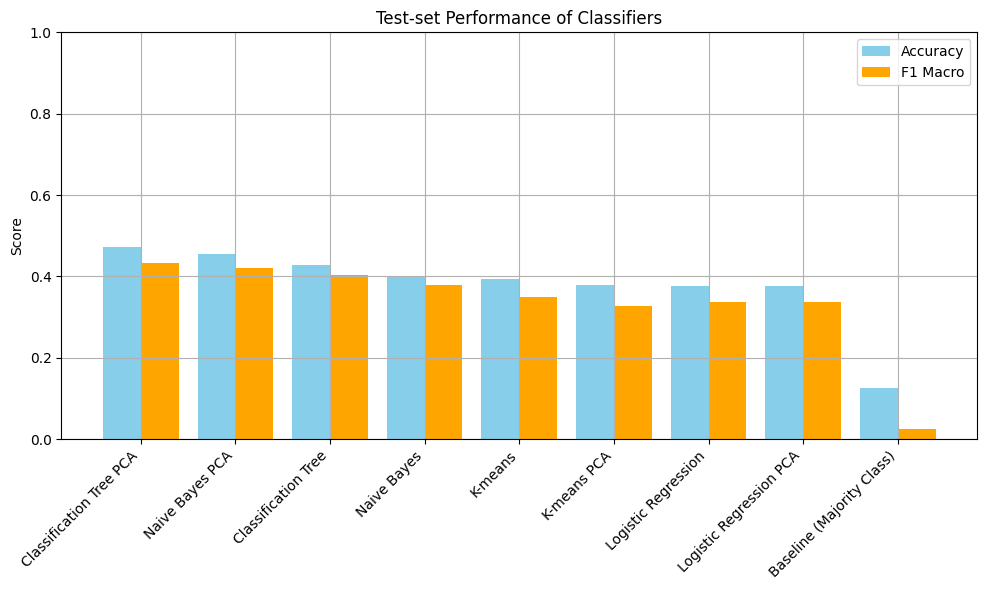

In [73]:
# Plot test-set performance of all classifiers
# Extract model names and their corresponding scores
models = results_test_df["Model"].values
accuracy = results_test_df["test_accuracy"].values
f1 = results_test_df["f1_score"].values

# X-axis positions for the bars
x = np.arange(len(models))

# Width of each bar
width = 0.4 

# Plot a grouped bar chart comparing Accuracy and F1-macro
plt.figure(figsize=(10,6))
plt.bar(x - width/2, accuracy, width, label="Accuracy", color="skyblue")
plt.bar(x + width/2, f1, width, label="F1 Macro", color="orange")

# Set x-axis labels and rotate for readability
plt.xticks(x, models, rotation=45, ha="right")
plt.ylabel("Model")

# Set y-axis limits and labels
plt.ylim(0,1)
plt.ylabel("Score")
plt.title("Test-set Performance of Classifiers")

plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

**Identify the Best Performing Model**

In [74]:
# Get the name of the top-performing model (highest test accuracy)
best_name = results_test_df.iloc[0]["Model"]

# Get the corresponding dictionary from the results
best_result = results.get(best_name)

# Extract the trained estimator object
best_est = best_result["best_model"]

# Extract best hyperparameters, test accuracy, and F1 score
best_params = best_result["best_params"]
best_test_acc = best_result["test_accuracy"]
best_f1 = best_result["f1_score"]

# Print summary of the best model
print("Best Model Name:", best_name)
print("Best Estimator Object:", best_est)
print("Best Params:", best_params)
print("Test Accuracy:", best_test_acc)
print("Test F1 (macro):", best_f1)

Best Model Name: Classification Tree PCA
Best Estimator Object: DecisionTreeClassifier(max_depth=15, random_state=123)
Best Params: {'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2}
Test Accuracy: 0.4727592267135325
Test F1 (macro): 0.4336996713438053


#### **Expected Performance on New (Unseen) Data**

To understand the performance of the trained classifiers we used a baseline majority class classifier. This model always predicts the most frequent class in the training data and serves as a minimal benchmark for comparison [17]. The baseline achieved a test accuracy of $0.125$ and a macro averaged F1 score of $0.025$, which indicates extremely poor predicitve capability and a very poor performance in identifying minority classes. This highlights that meaningful learning is required to achieve an acceptable performance on the multiclass classification dataset.

The usefulness of each trained classifier for predicting the class of new and unseen data is accessed using test set accuracy and a macro averaged F1 score, which together provide insight into both overall correctness and balanced performance across classes.

##### **Classification Tree**

The classification tree classifier demonstrates strong predictive performance particularly when combined with PCA. The PCA based classification tree achieves the highest test accuracy of $0.473$ and the highest macro averaged F1 score of $0.434$ compared to the other classifiers. PCA reduces dimensionality and removes noise, which allows the tree to focus on the most informative components and imporves generalisation. Although classification trees are prone to overfitting this risk is reduced through the use of validation data set based hyperparameter tuning and dimensionality reduction of the dataset, which makes the model reliable for unseen data.

##### **Naïve Bayes**

Naïve Bayes shows moderate performance with accuracy and F1 score improving after applying PCA. The Naïve Bayes PCA model achieves a test accuracy of $0.455$ and a macro averaged F1 score of $0.420$, which indicates reasonable generalisation. However, its performance is limited due to the model assuming all features are independent, which doesn't occur in image-based data such as MNIST where pixel intensities are highly correlated.

##### **Logistic Regression**

Logistic regression performs poorly relative to the other models and achieves a test accuracy of $0.376$ and a macro averaged F1 score of $0.337$ with and without the use of PCA. This suggests that a linear decision surface is insufficient to capture the complex non-linear structure of the handwritten digit images. Even with scaling and dimensionality reduction logistic regression lacks the expressive power required for this dataset.

##### **K-means Clustering Classifier**

The k-means clustering classifier achieves a moderate level of performance with a test accuarcy of $0.394$ and a macro averaged macro F1 score of $0.349$ without PCA and with PCA it achieves a test accuarcy of $0.380$ and a macro averaged macro F1 score of $0.328$. While it performs worse than the supervised classification tree and Naïve Bayes classifiers, it outperoforms the logistic regression classifier with and without PCA. Although the model is able to capture some underlying structure in the data, k-means clustering is an unsupervised algorithm and does not directly optimise class separation.

Increasing the number of clusters per class generally improves classification performance as it allows the model to better approximate complex class distributions. However, this improvement comes at the cost of increased computational complexity and reduced scalability. As the number of clusters increases the training time grows substantially and the manhattan distance based classification step becomes more expensive to compute, which limits practical performance gains.

Furthermore, using a large number of clusters risks overfitting the training data by modelling noise rather than generalisable patterns. As a result the k-means classifier represents a trade-off between model flexibility and computational efficiency.

#### **Final Model Recommendation**

Based on the test set evaluation the classification tree with PCA is the most suitable classifier to use for this dataset. 

This decision is based on the following observations:

- It achieves the highest test accuarcy of $0.473$ compared to the other classifiers,
- It achieves the highest macro averaged F1 score $0.473$ compared to the other classifiers, which indicates balanced performance acorss all classes,
- It demonstrates a substantial improvement over the baseline majority class classifier, which confirms that meanginful patterns are learned from the data,
- Dimensionality reduction using PCA improves generalisation by reducing noise and redundant feature correlations,
- The model is capable of learning non-linear decision surfaces, which are essential for capturing the complex structure of handwritten digit images.

Although Naïve Bayes with PCA performs competitively its strong independence assumption limits its ability to fully capture feature dependencies present in the image data. Logistic regression performs poorly due to its linear decision surface and k-means clustering classifier is constrained by its unsupervised nature and computational trade-offs. 

#### **Conclusion**

This study investigated the performance of several supervised and unsupervised learning algorithms on a randomly sampled subset of the MNIST handwritten digits dataset using test set accuracy and macro averaged F1 score to evaluate predictive performance on unseen observations. A baseline majority class classifier was first established to provide a reference point against the performance of the trained classifiers.

The results show that the supervised learning methods consistently outperform the unsupervised approaches with dimensionality reduction using PCA providing benefit for two of the models (classification tree and Naïve Bayes). Among all evaluated classifiers the classification tree combined with PCA achieved the best overall performance, which demonstrates strong generalisation and balanced class predictions. This highlights the importance of both non-linear modelling capacity and effective feature reduction when working with high dimensional image data.

While Naïve Bayes with PCA performed competitively its independent features assumption limited its ability to fully exploit feature correlations. Logistic regression proved unsuitable due to its reliance on linear decision surfaces and although the k-means clustering classifier captured some underlying structure its unsupervised nature and computational trade-offs limited its effectiveness.

The classification accuracy achieved by all model is moderate compared to approaches specifically designed for the MNIST dataset. This is expected given the use of classical machine learning models and a limited feature representation. The results remain meaningful as all evaluated classifiers substantially outperform the baseline model.

Overall, the findings highlight that models capable of learning non-linear decision surfaces when combined with appropiate dimensionality reduction are best suited for image based classification tasks. Future work could explore deep learning approaches such as convolutional neural networks (CNN) [25]. CNN is specifically designed for image based data and may further improve classification performance and scalability.

---

#### **References**

[1] Coursework Details (Accessed on 12/12/2025) https://canvas.qub.ac.uk/courses/33616/assignments/227716

[2] Information about the MNIST Dataset by Anurag (Accessed on 12/12/2025) https://www.geeksforgeeks.org/machine-learning/mnist-dataset/

[3] Page 1 Section 4.1 from Chapter 4 of Lecture Notes (Accessed on 16/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705298?module_item_id=1579969

[4] Page 6 Section 2.3.1 from Chapter 2 of Lecture Notes (Accessed on 16/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705295?module_item_id=1579967

[5] Page 18 Section 4.4 from Chapter 4 of Lecture Notes (Accessed on 16/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705298?module_item_id=1579969

[6] Clustering Practical Solutions from Practical Sessions (Accessed on 15/12/2025) https://canvas.qub.ac.uk/courses/33616/files/7089267?module_item_id=1673170

[7] Davies-Bouldin Index by Phalashi S (Accessed on 17/12/2025) https://www.geeksforgeeks.org/machine-learning/davies-bouldin-index/

[8] Page 6 Section 4.3 from Chapter 4 of Lecture Notes (Accessed on 16/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705298?module_item_id=1579969

[9] Page 3 Section 4.1.1 and Page 18 Section 4.4 from Chaper 4 of Lecture Notes (Accessed on 16/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705298?module_item_id=1579969

[10] Page 2 Section 5.1 from Chapter 5 of Lecture Notes (Accessed on 19/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705299?module_item_id=1579970

[11] Missing Data Practical Solutions from Practical Sessions (Accessed on 20/12/2025) https://canvas.qub.ac.uk/courses/33616/files/7089267?module_item_id=1673170

[12] Using R in python (All 3 where accessed on 21/12/2025)

https://stackoverflow.com/questions/58144737/mcar-littles-test-in-python

https://rviews.rstudio.com/2022/05/25/calling-r-from-python-with-rpy2/

https://rpy2.github.io/doc/v3.5.x/html/robjects_convert.html#local-conversion-rules

[13] Understanding Little’s MCAR Test: A Key Tool in Missing Data Analysis by Taran Kaur (Accessed on 21/12/2025) https://medium.com/@tarangds/understanding-littles-mcar-test-a-key-tool-in-missing-data-analysis-47fd70698149

[14] Mean/Median Imputation Section in Top Techniques to Handle Missing Values Every Data Scientist Should Know by Zoumana Keita (Accessed on 23/12/2025) https://www.datacamp.com/tutorial/techniques-to-handle-missing-data-values

[15] How to Avoid Data Leakage When Imputing for Predictive Modeling by TarekElnaccash (Accessed on 23/12/2025) https://communities.sas.com/t5/SAS-Communities-Library/How-to-Avoid-Data-Leakage-When-Imputing-for-Predictive-Modeling/ta-p/911876

[16] Train Test Validation Split: How To & Best Practices [2024] by Pragati Baheti (Accessed on 23/12/2026) https://www.v7labs.com/blog/train-validation-test-set

[17] Understanding Baseline Models in Machine Learning by Preethi Prakash (Accessed on 28/12/2025) https://medium.com/@preethi_prakash/understanding-baseline-models-in-machine-learning-3ed94f03d645

[18] DummyClassifier information (Accessed on 28/12/2025) https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

[19] Classification Practical Solutions from Practical Sessions (Accessed on 28/12/2025) https://canvas.qub.ac.uk/courses/33616/files/7128263?module_item_id=1678663

[20] Page 27 Section 5.3.2 from Chapter 5 of Lecture Notes (Accessed on 28/12/2025) https://canvas.qub.ac.uk/courses/33616/files/6705299?module_item_id=1579970

[21] 8 Key Advantages and Disadvantages of Decision Trees by Inside Learning Machines (Accessed on 28/12/2025) https://insidelearningmachines.com/advantages_and_disadvantages_of_decision_trees/

[22] Naive Bayes Explained: Function, Advantages & Disadvantages, Applications in 2025 by Pavan Vadapalli (Accessed on 28/12/2025) https://www.upgrad.com/blog/naive-bayes-explained/

[23] Advantages and Disadvantages of Logistic Regression by Amiya Rout (Accessed on 29/12/2025) https://www.geeksforgeeks.org/data-science/advantages-and-disadvantages-of-logistic-regression/

[24] What is Manhattan Distance? by Vinod Chugani (Accessed on 30/12/2025) https://www.datacamp.com/tutorial/manhattan-distance

[25] What are convolutional neural networks? on IBM (Accessed on 02/01/2026) https://www.ibm.com/think/topics/convolutional-neural-networks